[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/BVQC_Watermarking_Chu2025.ipynb)

# BVQC: backdoor-style watermarking of variational quantum circuits (Chu et al., 2025) step by step

**Paper.** Cheng Chu, Lei Jiang, Fan Chen. *BVQC: A Backdoor-Style Watermarking Scheme for Variational Quantum Circuits.* IEEE International Conference on Quantum Computing and Engineering (QCE), 2025. DOI [10.1109/QCE65121.2025.00081](https://doi.org/10.1109/qce65121.2025.00081), arXiv [2508.01893](https://arxiv.org/abs/2508.01893).

**The problem.** A trained variational quantum circuit (VQC) is intellectual property: a vendor sells the circuit and a customer could copy and resell it. The owner therefore wants to *prove authorship* of a circuit that someone else is running. Earlier quantum-circuit watermarks hide a signature in the *compilation* (gate decomposition, qubit mapping, gate scheduling). Those signatures are removed when the thief simply re-compiles the circuit, and the extra gates add noise.

**The idea of BVQC.** Hide the watermark in the *trained angles* instead of the gate structure. The circuit is trained on two tasks at once:

1. the normal task: with the normal input state and the normal observable, the loss is the minimum (for example the ground-state energy);
2. a secret *backdoor* task: with a secret input state and a secret observable, the loss must be a secret value `L_pre` that an unwatermarked circuit would not give.

The owner proves ownership by running the circuit on the secret input / observable and showing that the loss equals `L_pre`. Re-compiling does not change the angles, so the watermark survives; no extra gates are added, so the task loss is not harmed.

**What this notebook does (everything runs on a CPU, no quantum hardware needed).**

1. Loads the paper's Hamiltonians (PennyLane quantum-chemistry datasets for H2 and H3+) and builds MaxCut Hamiltonians for the two QAOA benchmarks.
2. Builds the four benchmark circuits (VQE-H2, VQE-H3+, QAOA-4, QAOA-6) in three equivalent forms (an exact fast PyTorch simulator, a PennyLane QNode and a Qiskit circuit) and asserts that they give identical numbers.
3. Trains non-watermarked circuits (NW) and watermarked circuits (BVQC) with the paper's loss, Eq. (1), with and without the *grouping* algorithm (Algorithm 1).
4. Runs the circuits on **noisy simulators of IBM Kolkata and of a second 27-qubit IBM device (Hanoi, standing in for the paper's Cairo)** with zero-noise extrapolation (ZNE), and computes the paper's ground-truth distance (GTD).
5. Re-compiles the circuits (other seeds, optimisation levels, another device) and checks that the watermark is unchanged.
6. Tests ownership verification (true and false positives) and adds removal attacks (fine-tuning, pruning, parameter noise) and a randomised-smoothing training variant that the paper only mentions.
7. Prints the paper's numbers next to this notebook's with a verdict per claim.

**How to run.** Open in Google Colab, choose a CPU runtime, `Runtime -> Run all`. `FAST_MODE = True` finishes in roughly 10-25 minutes of CPU simulation (it was timed at about 24 minutes on a CPU shared with many other jobs); `FAST_MODE = False` uses larger samples (budgets in the configuration cell, about one hour). No account or token is needed: the data come from public PennyLane dataset servers (with an offline fallback that recomputes the same Hamiltonians), and the device noise models are the fake backends shipped with `qiskit-ibm-runtime`.

**Important honesty note.** The paper ran on real IBM hardware (Kolkata, Cairo) and compared with a prior watermark by Yang et al. [12] that is not public. Here the devices are *simulated* from stored calibration data (gate noise only, no shot noise, no readout error), so absolute GTD values differ from the paper, and every comparison with the prior method (MS) is marked "cannot be checked".

## The paper in one page

**Problem and threat model.** Protect a VQC's authorship in a black-box setting. The adversary has the white-box circuit and the best compilers (Qiskit, BQSKit, PennyLane) and wants to remove the watermark by re-compiling, approximate synthesis, etc., while keeping the circuit useful. The adversary cannot train a VQC from scratch.

**Method.** Training loss (Eq. 1): `L(theta) = alpha * f(theta, rho_b, M_b) + beta * [ f(theta, rho_pre, M_pre) - L_pre ]^2`, where `f` is the expected value of an observable `M` for the circuit applied to the input state `rho`; `(rho_b, M_b)` is the normal input and observable, `(rho_pre, M_pre)` the secret ones and `L_pre` the secret target loss. The owner publishes the circuit and `(rho_b, M_b)` and keeps `(rho_pre, M_pre, L_pre)`.

**Grouping (Algorithm 1, Eq. 2-4).** Random candidate groups `(rho_pre, M_pre, L_pre)` are scored by how a gradient step on the *watermark* loss changes the *base* loss: `score_k = 1 - |f(theta_{k+1}) - L_opt|^2 / |f(theta_k) - L_opt|^2`, averaged over `S` steps. Groups with low conflict (the paper's "POS" groups) are kept; conflicting ("NEG") groups are rejected.

**Benchmarks (Table IV).** VQE-H2 (4 qubits), VQE-H3+ (6), QAOA-4 (4), QAOA-6 (6), VQD-H2 (9), VQD-H3+ (13), GEO-M; datasets: PennyLane molecules (H2, H3+) and HamLib MaxCut. Training: 300 epochs, Adam, learning rate 5e-3, weight decay 1e-4. Evaluation on IBM Kolkata and Cairo with Qiskit optimisation level 3 and ZNE.

**Metrics.** Ground-truth distance `GTD = |L_estimated - L_optimal|` (task GTD with base input/observable, watermark GTD against `L_pre`); Probabilistic Proof of Authorship (PPA, Eq. 6).

**Claims checked in this notebook** (paper values in the final table): BVQC keeps the task GTD (Table V, Fig. 7: average change 4.1e-3); the watermark GTD is small for BVQC and large for unwatermarked circuits (Table V); grouping lowers the base-task GTD / loss (Fig. 4-6); the watermark survives re-compilation with unchanged circuit structure (Table III, Fig. 8); fine-tuning is the strongest removal attack and smoothing helps (Sec. IV-E).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Hardware | IBM Kolkata and Cairo, real devices | `FakeKolkataV2` and `FakeHanoiV2` noise models in Qiskit Aer (density-matrix, exact expectation values, no readout error, no shot noise). `FakeCairoV2` of `qiskit-ibm-runtime` 0.50.0 has a broken coupling map (26 directed links, mixed `cx`/`ecr`) and cannot be transpiled to, so Hanoi (same 27-qubit Falcon family, `cx` native) replaces it (`# CHOICE`) |
| Error mitigation | digital ZNE [32], details not given | global unitary folding with scales 1, 3, 5 and Richardson extrapolation (`# CHOICE`) |
| H2 / H3+ Hamiltonians | PennyLane qchem datasets, Jordan-Wigner | same dataset (STO-3G, H2 0.742 A, H3+ 0.874 A); offline fallback recomputes it |
| MaxCut graphs | "random 4-node and 6-node graph" from HamLib | random connected graphs with 5 and 6 edges from `networkx` (HamLib files are large, not mirrored) (`# CHOICE`) |
| VQE ansatz | "ansatz from [29]", Table IV gives 24 / 72 one-qubit and 8 / 24 two-qubit gates | RY-RZ layers separated by ring-CNOT layers: 24 / 60 and 8 / 24 gates (H3+ has 60 instead of 72 one-qubit gates) (`# CHOICE`) |
| QAOA ansatz | circuit of [30] with 40 / 54 one-qubit and 40 / 48 two-qubit gates | depth p = 4, one free angle per RZZ and per RX gate (`CX RZ CX` per edge): 40 / 54 and 40 / 48 gates, exactly as in Table IV (`# CHOICE`: free angle per gate, so that the circuit has capacity for the watermark) |
| VQD-H2, VQD-H3+, GEO-M | benchmarks 5-7 | **not implemented** (VQD needs 9 / 13 qubits with swap tests, GEO-M data not identified); all claims on 7 benchmarks are checked on 4 |
| Base input / observable | |0...0>, the problem Hamiltonian | same; `L_opt` is the lowest eigenvalue of the Hamiltonian matrix (for H3+ the lowest eigenvalue over all particle sectors, -1.297, not the FCI value -1.262) |
| Predefined input `rho_pre` | "differs in amplitude or phase" | product state `RZ(b) RY(a) |0>` per qubit with random angles (`# CHOICE`) |
| Predefined observable `M_pre` | random Pauli sum, e.g. `0.1YY + 0.1ZZ + 0.3XY` | 4 random Pauli words of weight 1-2 with weights in +-[0.3, 1] (`# CHOICE`) |
| `L_pre` | 0 (VQE, VQD), 1 (QAOA-4), -1 (QAOA-6), Table V | same values |
| alpha, beta | not given | alpha = beta = 1 (`# CHOICE`) |
| Optimiser | Adam, lr 5e-3, wd 1e-4, 300 epochs, TorchQuantum | Adam, wd 1e-4, 300 epochs, **lr 5e-2** (`# CHOICE`: with lr 5e-3 the VQE circuits do not converge in 300 epochs, shown in a cell below) |
| Grouping | Algorithm 1; sign rule contradictory (algorithm says accept `score < 0`, text and Fig. 5 say positive is good) | candidates scored with Eq. 3-4 on plain gradient steps from a trained NW circuit; "POS" = best-scored candidates, "NEG" = worst-scored (`# CHOICE`, following the text and Fig. 5) |
| Samples | 50 watermark groups per benchmark | `K_ARM` per arm (3 in FAST_MODE, 16 in the full run) |
| Prior method MS [12] | baseline for PPA and GTD | not public, **cannot be checked** |
| PPA | Eq. 6 on the number of satisfied constraints | not computable without the MS constraints; replaced by the invariance of the watermark value under re-compilation and by empirical true/false-positive rates |

## 0. Installation and configuration

The install cell only runs on Colab (or when an import fails locally). Versions are the tested ones. On Colab a runtime restart is not normally needed, but if an import error appears right after installing, restart the runtime and run all cells again.

In [1]:
import importlib, os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
def _missing():
    for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime", "torch", "networkx"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False
if IN_COLAB or _missing():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "qiskit==2.5.2", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "pylatexenc", "networkx", "h5py", "aiohttp", "requests"], check=False)
print("IN_COLAB =", IN_COLAB)

IN_COLAB = False


In [2]:
# ----------------------------------------------------------------------------------------------
# CONFIGURATION: every tunable constant lives here.
# ----------------------------------------------------------------------------------------------
SEED = 42
FAST_MODE = False             # True: a few minutes of simulation (class demo). False: larger samples (see below).
DATA_DIR = "bvqc_data"        # downloads / caches (Hamiltonians as JSON); created next to the notebook
IBM_TOKEN = ""                # optional; NOT needed: devices are simulated with fake backends (real hardware is never used)

BENCHMARKS = ["VQE-H2", "VQE-H3+", "QAOA-4", "QAOA-6"]    # VQD-H2, VQD-H3+, GEO-M of the paper are not implemented

# --- training (paper: 300 epochs, Adam, lr 5e-3, weight decay 1e-4) ---
EPOCHS = 300
LR = 5e-2                     # CHOICE: 10x the paper's 5e-3, see the convergence check in section 4
PAPER_LR = 5e-3
WEIGHT_DECAY = 1e-4
ALPHA, BETA = 1.0, 1.0        # CHOICE: weights of the base and the watermark term in Eq. (1)

# --- watermark groups and grouping algorithm ---
L_PRE = {"VQE-H2": 0.0, "VQE-H3+": 0.0, "QAOA-4": 1.0, "QAOA-6": -1.0}   # Table V
MIN_SEP = 0.3                 # CHOICE: a candidate is kept only if an NW circuit misses L_pre by at least this much (unambiguity)
FEASIBLE_MARGIN = 0.3         # CHOICE: L_pre must lie this far inside the spectrum of M_pre
GROUP_LR = 0.05               # CHOICE: step size of the plain gradient steps used to score a candidate (Eq. 3)
TAU = 0.1                     # CHOICE: ownership is accepted when |f(rho_pre, M_pre) - L_pre| <= TAU
ZNE_SCALES = (1, 3, 5)        # CHOICE: noise scale factors of the digital ZNE
SMOOTH_SIGMA = 0.1            # CHOICE: std of the parameter noise used in the smoothing variant (extension)
FT_LR = 1e-2                  # learning rate of the attacker's fine-tuning

if FAST_MODE:
    K_ARM = 3                 # watermarked circuits per arm (random / POS / NEG) and non-watermarked circuits per benchmark
    N_CAND = 16               # candidate groups scored by the grouping algorithm
    GROUP_STEPS = 10          # S in Eq. (4)
    N_NOISY = 2               # circuits per benchmark evaluated on each noisy device
    N_ATTACK = 2              # circuits per benchmark attacked
    ATTACK_STEPS = (0, 100, 200)
else:                         # full run; about 1 h on a shared 8-core CPU (the paper uses 50 groups per benchmark)
    K_ARM = 10
    N_CAND = 60
    GROUP_STEPS = 20
    N_NOISY = 4
    N_ATTACK = 3
    ATTACK_STEPS = (0, 100, 300)
print(dict(FAST_MODE=FAST_MODE, K_ARM=K_ARM, N_CAND=N_CAND, N_NOISY=N_NOISY, EPOCHS=EPOCHS, LR=LR))

{'FAST_MODE': False, 'K_ARM': 10, 'N_CAND': 60, 'N_NOISY': 4, 'EPOCHS': 300, 'LR': 0.05}


In [3]:
import json, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import pennylane as qml
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeKolkataV2, FakeHanoiV2
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
np.random.seed(SEED); torch.manual_seed(SEED)
rng_master = np.random.default_rng(SEED)
CD = torch.complex128
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)
T_START = time.time()

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0


## 1. The simulator and the benchmark circuits

Training a circuit needs thousands of gradient steps, and the watermark is trained jointly on two inputs, so a generic simulator would be too slow on a shared CPU. The next cells define an **exact, batched PyTorch state-vector simulator** (`K` independent circuits at once, automatic differentiation) for the two ansatz families. The very same gate list is also turned into a PennyLane QNode and a Qiskit circuit, and section 3 asserts that all three give identical expectation values. Conventions: qubit 0 is the first character of a Pauli word; `RY(a)`, `RZ(b)`, `RX(c)` are the usual rotations `exp(-i angle P / 2)`.

In [4]:
PAULI = {"I": np.eye(2, dtype=complex), "X": np.array([[0, 1], [1, 0]], dtype=complex),
         "Y": np.array([[0, -1j], [1j, 0]], dtype=complex), "Z": np.diag([1, -1]).astype(complex)}


def dense_from_words(coeffs, words):
    """Dense matrix of sum_k c_k P_k; the first character of a word acts on qubit 0 (most significant bit)."""
    n = len(words[0])
    M = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for c, w in zip(coeffs, words):
        m = np.array([[1.0 + 0j]])
        for ch in w:
            m = np.kron(m, PAULI[ch])
        M += c * m
    return M


# ---------------- exact batched simulator (torch, autograd) -----------------
# Every function works on a batch of K parameter vectors at once (K independent circuits).
def ry_batch(t):   # t: (...,) -> (...,2,2)
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(CD)


def rz_batch(t):
    e = torch.exp(-0.5j * t.to(CD)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)


def rx_batch(t):
    c = torch.cos(t / 2).to(CD); s = -1j * torch.sin(t / 2).to(CD)
    return torch.stack([torch.stack([c, s], -1), torch.stack([s, c], -1)], -2)


def kron_batch(mats):
    """mats: (K, n, 2, 2) -> (K, 2^n, 2^n), qubit 0 = most significant."""
    out = mats[:, 0]
    for q in range(1, mats.shape[1]):
        K, a, b = out.shape
        out = torch.einsum("kab,kcd->kacbd", out, mats[:, q]).reshape(K, a * 2, b * 2)
    return out


def _bits(n):
    """(2^n, n) array of bits, qubit 0 = most significant."""
    return ((np.arange(2 ** n)[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1)


class VQEAnsatz:
    """Hardware-efficient ansatz: (L+1) layers of RY,RZ on every qubit, L ring-CNOT layers in between."""
    kind = "vqe"

    def __init__(self, n, L):
        self.n, self.L = n, L
        self.n_params = 2 * n * (L + 1)
        bits = _bits(n).copy()
        out = bits.copy()
        for q in range(n):                      # ring of CNOTs (0,1),(1,2),...,(n-1,0) as an amplitude permutation
            out[:, (q + 1) % n] ^= out[:, q]
        new_idx = (out * (1 << (n - 1 - np.arange(n)))[None, :]).sum(1)
        inv = np.empty_like(new_idx); inv[new_idx] = np.arange(2 ** n)
        self.inv = torch.tensor(inv, dtype=torch.long)
        self.gates = []                         # gate list shared by the PennyLane and Qiskit versions
        k = 0
        for l in range(L + 1):
            for q in range(n):
                self.gates.append(("ry", q, k)); self.gates.append(("rz", q, k + 1)); k += 2
            if l < L:
                for q in range(n):
                    self.gates.append(("cx", q, (q + 1) % n))

    def state(self, theta, psi):                # theta (K,P), psi (K,dim)
        K = theta.shape[0]
        th = theta.reshape(K, self.L + 1, self.n, 2)
        for l in range(self.L + 1):
            R = kron_batch(rz_batch(th[:, l, :, 1]) @ ry_batch(th[:, l, :, 0]))
            psi = torch.einsum("kij,kj->ki", R, psi)
            if l < self.L:
                psi = psi[:, self.inv]
        return psi


class QAOAAnsatz:
    """QAOA for MaxCut with one free angle per gate: H^n, then p x [ CX RZ(theta_e) CX on every edge, RX(theta_v) on every node ]."""
    kind = "qaoa"

    def __init__(self, n, edges, p):
        self.n, self.edges, self.p = n, list(edges), p
        E = len(self.edges)
        self.n_params = p * (E + n)
        z = 1 - 2 * _bits(n)
        self.zz = torch.tensor(np.stack([z[:, i] * z[:, j] for i, j in self.edges], 1), dtype=torch.float64)
        self.Hn = torch.tensor(np.array([[1.0]]), dtype=CD)
        h1 = torch.tensor([[1, 1], [1, -1]], dtype=CD) / np.sqrt(2)
        self.Hn = kron_batch(h1[None, None].expand(1, n, 2, 2))[0]
        self.gates = [("h", q, None) for q in range(n)]
        k = 0
        for _ in range(p):
            for (i, j) in self.edges:
                self.gates += [("cx", i, j), ("rz", j, k), ("cx", i, j)]; k += 1
            for q in range(n):
                self.gates.append(("rx", q, k)); k += 1

    def state(self, theta, psi):
        n, E, K = self.n, len(self.edges), theta.shape[0]
        th = theta.reshape(K, self.p, E + n)
        psi = psi @ self.Hn.T
        for l in range(self.p):
            phase = torch.exp(-0.5j * (th[:, l, :E] @ self.zz.T).to(CD))      # exp(-i/2 sum_e theta_e Z_i Z_j)
            psi = phase * psi
            R = kron_batch(rx_batch(th[:, l, E:]))
            psi = torch.einsum("kij,kj->ki", R, psi)
        return psi


def product_state(a, b):
    """RZ(b_q) RY(a_q) |0> on every qubit as a flat vector (a, b: numpy arrays of length n)."""
    ta, tb = torch.tensor(np.asarray(a, float)), torch.tensor(np.asarray(b, float))
    m = (rz_batch(tb) @ ry_batch(ta))[:, :, 0:1]            # (n,2,1)
    out = m[0]
    for q in range(1, m.shape[0]):
        out = torch.kron(out, m[q])
    return out.reshape(-1)


In [5]:
class Bench:
    def __init__(self, name, ansatz, words, coeffs, l_pre):
        self.name, self.ans, self.words, self.coeffs, self.l_pre = name, ansatz, list(words), list(coeffs), l_pre
        self.n = ansatz.n
        self.H = dense_from_words(coeffs, words)
        self.Ht = torch.tensor(self.H, dtype=CD)
        self.l_opt = float(np.linalg.eigvalsh(self.H)[0])
        self.psi0 = torch.zeros(2 ** self.n, dtype=CD); self.psi0[0] = 1

    def energy(self, theta, psi_in=None, M=None):
        """<psi_in| U(theta)^dag M U(theta) |psi_in> for a batch of thetas (K,P) -> (K,)."""
        K = theta.shape[0]
        psi_in = self.psi0 if psi_in is None else psi_in
        psi_in = psi_in.expand(K, -1) if psi_in.dim() == 1 else psi_in
        psi = self.ans.state(theta, psi_in)
        M = self.Ht if M is None else M
        if M.dim() == 2:
            return ((psi.conj() @ M.T) * psi).sum(1).real
        return torch.einsum("ki,kij,kj->k", psi.conj(), M, psi).real


def random_measurement(n, rng, n_terms=4, wmin=0.3, wmax=1.0):
    """Predefined measurement: weighted sum of random non-identity Pauli words of weight 1 or 2 (cf. paper's 0.1YY+0.1ZZ+0.3XY)."""
    words, coeffs = [], []
    while len(words) < n_terms:
        wt = int(rng.integers(1, 3))
        qs = rng.choice(n, size=wt, replace=False)
        chars = ["I"] * n
        for q in qs:
            chars[q] = str(rng.choice(["X", "Y", "Z"]))
        w = "".join(chars)
        if w not in words:
            words.append(w); coeffs.append(float(rng.uniform(wmin, wmax) * rng.choice([-1, 1])))
    return words, coeffs


class WMConfig:
    """One watermark group (rho_pre, M_pre, L_pre)."""
    def __init__(self, bench, rng):
        n = bench.n
        self.a = rng.uniform(0.3, np.pi - 0.3, n); self.b = rng.uniform(-np.pi, np.pi, n)
        self.words, self.coeffs = random_measurement(n, rng)
        self.l_pre = bench.l_pre
        self.psi = product_state(self.a, self.b)
        self.M = torch.tensor(dense_from_words(self.coeffs, self.words), dtype=CD)


def stack_wm(wms):
    return torch.stack([w.psi for w in wms]), torch.stack([w.M for w in wms]), torch.tensor([w.l_pre for w in wms])


def train(bench, theta0, epochs, lr, wd, wms=None, alpha=1.0, beta=1.0, smooth_sigma=0.0, seed=0, record=0, snap=()):
    """Adam on  alpha*f(theta,rho_b,M_b) + beta*(f(theta,rho_pre,M_pre)-L_pre)^2   (Eq. 1) for K independent circuits at once.
    theta0: (K,P); wms: list of K WMConfig (None -> plain training = no watermark). Returns (theta (K,P), history list of (epoch, base_loss (K,)), {epoch: theta} snapshots)."""
    th = torch.nn.Parameter(theta0.clone())
    opt = torch.optim.Adam([th], lr=lr, weight_decay=wd)
    g = torch.Generator().manual_seed(seed)
    if wms is not None:
        P, Ms, Lp = stack_wm(wms)
    hist, snaps = [], {}
    if 0 in snap:
        snaps[0] = th.detach().clone()
    for e in range(epochs):
        opt.zero_grad()
        fb = bench.energy(th)
        loss = alpha * fb.sum()
        if wms is not None:
            t2 = th + smooth_sigma * torch.randn(th.shape, generator=g) if smooth_sigma > 0 else th
            fw = bench.energy(t2, P, Ms)
            loss = loss + beta * ((fw - Lp) ** 2).sum()
        loss.backward(); opt.step()
        if (e + 1) in snap:
            snaps[e + 1] = th.detach().clone()
        if record and (e % record == 0 or e == epochs - 1):
            hist.append((e, fb.detach().numpy().copy()))
    return th.detach(), hist, snaps


def wm_value(bench, theta, wms):
    with torch.no_grad():
        P, Ms, _ = stack_wm(wms)
        return bench.energy(theta, P, Ms).numpy()


def base_value(bench, theta):
    with torch.no_grad():
        return bench.energy(theta).numpy()


In [6]:
# ---------------- Qiskit circuit from the shared gate list ----------------
def qiskit_circuit(bench, theta, wm=None):
    """Circuit that is executed: [optional predefined-input preparation RY,RZ per qubit] + ansatz (from the gate list)."""
    th = np.asarray(theta, float)
    qc = QuantumCircuit(bench.n)
    if wm is not None:
        for q in range(bench.n):
            qc.ry(float(wm.a[q]), q); qc.rz(float(wm.b[q]), q)
    for g in bench.ans.gates:
        name, a, b = g
        if name == "cx":
            qc.cx(a, b)
        elif name == "h":
            qc.h(a)
        elif name == "ry":
            qc.ry(th[b], a)
        elif name == "rz":
            qc.rz(th[b], a)
        elif name == "rx":
            qc.rx(th[b], a)
    return qc


def sparse_op(words, coeffs):
    """Qiskit labels are little-endian: our word character i acts on qubit i -> reverse the string."""
    return SparsePauliOp([w[::-1] for w in words], coeffs)


def ideal_value_qiskit(bench, theta, wm=None):
    qc = qiskit_circuit(bench, theta, wm)
    op = sparse_op(wm.words, wm.coeffs) if wm is not None else sparse_op(bench.words, bench.coeffs)
    return float(Statevector(qc).expectation_value(op).real)


# ---------------- PennyLane QNode from the same gate list ----------------
def pennylane_qnode(bench, with_prep=False):
    dev = qml.device("default.qubit", wires=bench.n)

    @qml.qnode(dev)
    def circuit(params, a=None, b=None, words=None, coeffs=None):
        if with_prep:
            for q in range(bench.n):
                qml.RY(a[q], wires=q); qml.RZ(b[q], wires=q)
        for name, x, y in bench.ans.gates:
            if name == "cx":
                qml.CNOT(wires=[x, y])
            elif name == "h":
                qml.Hadamard(wires=x)
            elif name == "ry":
                qml.RY(params[y], wires=x)
            elif name == "rz":
                qml.RZ(params[y], wires=x)
            elif name == "rx":
                qml.RX(params[y], wires=x)
        ws, cs = (words, coeffs) if words is not None else (bench.words, bench.coeffs)
        obs = [qml.pauli.string_to_pauli_word(w) if set(w) != {"I"} else qml.Identity(0) for w in ws]
        return qml.expval(qml.dot(cs, obs))
    return circuit


In [7]:
# ---------------- noisy execution with zero-noise extrapolation ----------------
def two_qubit_basis(tq):
    ops = tq.count_ops()
    for g in ("cx", "ecr", "cz"):
        if g in ops:
            return g
    return "cx"


def fold_circuit(tq, scale):
    """Global unitary folding U (U^dag U)^k with noise scale 2k+1 (digital ZNE, Giurgica-Tiron et al. 2020)."""
    k = (scale - 1) // 2
    out = tq.copy()
    if k == 0:
        return out
    inv = tq.inverse()
    for _ in range(k):
        out.barrier(); out.compose(inv, inplace=True); out.barrier(); out.compose(tq, inplace=True)
    return out


def richardson(scales, vals):
    """Polynomial (degree len-1) extrapolation to scale 0."""
    s = np.asarray(scales, float); v = np.asarray(vals, float)
    return float(np.polyval(np.polyfit(s, v, len(s) - 1), 0.0))


class NoisyDevice:
    def __init__(self, backend, name):
        self.backend, self.name = backend, name
        self.sim = AerSimulator.from_backend(backend, method="density_matrix")

    def compile(self, qc, seed=0, level=3):
        return transpile(qc, self.backend, optimization_level=level, seed_transpiler=seed)

    def expval(self, tq, words, coeffs, scales=(1, 3, 5)):
        """Noisy <M> of a compiled circuit for every ZNE scale, plus Richardson-extrapolated value."""
        op = sparse_op(words, coeffs).apply_layout(tq.layout) if tq.layout is not None else sparse_op(words, coeffs)
        basis = ["rz", "sx", "x", two_qubit_basis(tq)]
        vals = []
        for s in scales:
            c = fold_circuit(tq, s)
            if s > 1:
                c = transpile(c, basis_gates=basis, optimization_level=0)
            c.save_expectation_value(op, list(range(c.num_qubits)), label="e")
            r = self.sim.run(c).result().data(0)["e"]
            vals.append(float(np.real(r)))
        return vals, richardson(scales, vals)


_IDEAL = AerSimulator(method="statevector")


def ideal_expval_compiled(tq, words, coeffs):
    """Noise-free expectation of a compiled (physical-qubit) circuit; the observable is mapped through the layout."""
    op = sparse_op(words, coeffs).apply_layout(tq.layout) if tq.layout is not None else sparse_op(words, coeffs)
    c = tq.copy()
    c.save_expectation_value(op, list(range(c.num_qubits)), label="e")
    return float(np.real(_IDEAL.run(c).result().data(0)["e"]))


## 2. Data: Hamiltonians and graphs

* **VQE-H2** and **VQE-H3+**: the molecular Hamiltonians of the PennyLane quantum-chemistry datasets (the paper's "PennyLane Molecules"), STO-3G basis, Jordan-Wigner mapping, 4 and 6 qubits. The base input is `|0...0>`, the base observable is the Hamiltonian, and `L_opt` is its lowest eigenvalue.
* **QAOA-4** and **QAOA-6**: MaxCut on a random connected graph with 4 nodes / 5 edges and 6 nodes / 6 edges. The observable is `C = sum_(i,j) -(1 - Z_i Z_j)/2`, so `L_opt = -(maximum cut)`.

The dataset download goes through `qml.data.load`; if the server is unreachable the cell recomputes the identical Hamiltonian from the molecular geometry (also public, offline). The Pauli terms are cached as JSON in `DATA_DIR`.

In [8]:
A2B = 1 / 0.529177210903     # Angstrom -> Bohr

def get_hamiltonian(mol, bondlength):
    fn = os.path.join(DATA_DIR, f"ham_{mol.replace('+', 'plus')}.json")
    if os.path.exists(fn):
        return json.load(open(fn))
    try:
        ds = qml.data.load("qchem", molname=mol, basis="STO-3G", bondlength=bondlength,
                           folder_path=os.path.join(DATA_DIR, "pl_data"))[0]
        H = ds.hamiltonian; n = len(H.wires); coeffs, ops = H.terms()
        wmap = {w: i for i, w in enumerate(H.wires)}
        out = dict(source="PennyLane dataset qchem", mol=mol, bondlength=float(ds.bondlength), n=n, fci=float(ds.fci_energy),
                   coeffs=[float(c) for c in coeffs], words=[qml.pauli.pauli_word_to_string(o, wire_map=wmap) for o in ops])
    except Exception as e:
        print(f"[{mol}] dataset download failed ({type(e).__name__}); recomputing the Hamiltonian from the geometry instead")
        if mol == "H2":
            sym, xyz, ch = ["H", "H"], np.array([[0, 0, 0], [0, 0, bondlength]]), 0
        else:
            d = bondlength
            sym, xyz, ch = ["H"] * 3, np.array([[0, 0, 0], [d, 0, 0], [d / 2, d * math.sqrt(3) / 2, 0]]), 1
        H, n = qml.qchem.molecular_hamiltonian(sym, xyz * A2B, charge=ch, basis="sto-3g", mapping="jordan_wigner")
        coeffs, ops = H.terms()
        wmap = {i: i for i in range(n)}
        words = [qml.pauli.pauli_word_to_string(o, wire_map=wmap) for o in ops]
        ev = np.linalg.eigvalsh(dense_from_words(coeffs, words))
        out = dict(source="recomputed with qml.qchem", mol=mol, bondlength=bondlength, n=n, fci=float(ev[0]),
                   coeffs=[float(c) for c in coeffs], words=words)
    json.dump(out, open(fn, "w"))
    return out

HAM = {"H2": get_hamiltonian("H2", 0.742), "H3+": get_hamiltonian("H3+", 0.874)}

def make_maxcut(n, n_edges, seed):
    for s in range(seed, seed + 1000):                    # CHOICE: first connected G(n, m) graph from this seed
        G = nx.gnm_random_graph(n, n_edges, seed=s)
        if nx.is_connected(G):
            return G

def maxcut_words(G):
    n = G.number_of_nodes(); words, coeffs = ["I" * n], [-G.number_of_edges() / 2]
    for i, j in G.edges():
        w = ["I"] * n; w[i] = "Z"; w[j] = "Z"
        words.append("".join(w)); coeffs.append(0.5)
    return words, coeffs

GRAPHS = {"QAOA-4": make_maxcut(4, 5, SEED), "QAOA-6": make_maxcut(6, 6, SEED)}
BENCH = {}
for name in BENCHMARKS:
    if name.startswith("VQE"):
        mol = name.split("-")[1]; h = HAM[mol]
        BENCH[name] = Bench(name, VQEAnsatz(h["n"], 2 if mol == "H2" else 4), h["words"], h["coeffs"], L_PRE[name])
    else:
        G = GRAPHS[name]; w, c = maxcut_words(G)
        BENCH[name] = Bench(name, QAOAAnsatz(G.number_of_nodes(), list(G.edges()), 4), w, c, L_PRE[name])

PAPER_T4 = {"VQE-H2": (4, 24, 8), "VQE-H3+": (6, 72, 24), "QAOA-4": (4, 40, 40), "QAOA-6": (6, 54, 48)}
rows = []
for name, b in BENCH.items():
    g = b.ans.gates
    rows.append(dict(benchmark=name, qubits=b.n, trainable_params=b.ans.n_params, one_qubit_gates=sum(1 for x in g if x[0] != "cx"),
                     two_qubit_gates=sum(1 for x in g if x[0] == "cx"), paper_Table_IV=PAPER_T4[name],
                     hamiltonian_terms=len(b.words), L_opt=round(b.l_opt, 4), L_pre=b.l_pre))
display(pd.DataFrame(rows))
print("H2 source:", HAM["H2"]["source"], "| H3+ source:", HAM["H3+"]["source"])
print("FCI energies from the dataset: H2 %.4f, H3+ %.4f" % (HAM["H2"]["fci"], HAM["H3+"]["fci"]))
for k in ("QAOA-4", "QAOA-6"):
    print(k, "edges:", list(GRAPHS[k].edges()))

,benchmark,qubits,trainable_params,one_qubit_gates,two_qubit_gates,paper_Table_IV,hamiltonian_terms,L_opt,L_pre
0,VQE-H2,4,24,24,8,"(4, 24, 8)",15,-1.1373,0.0
1,VQE-H3+,6,60,60,24,"(6, 72, 24)",66,-1.2973,0.0
2,QAOA-4,4,36,40,40,"(4, 40, 40)",6,-4.0000,1.0
3,QAOA-6,6,48,54,48,"(6, 54, 48)",7,-5.0000,-1.0


H2 source: PennyLane dataset qchem | H3+ source: PennyLane dataset qchem
FCI energies from the dataset: H2 -1.1373, H3+ -1.2622
QAOA-4 edges: [(0, 3), (0, 1), (1, 2), (1, 3), (2, 3)]
QAOA-6 edges: [(0, 5), (0, 4), (0, 1), (1, 2), (1, 4), (3, 4)]


## Dataset Exploration and Visualisation

The "data" of this paper are Hamiltonians, not labelled samples, so the ground-truth labels used below are the physical ones: the Pauli-term family of every Hamiltonian term, the particle-number sector of every computational basis state, and the cut value of every bit string of the MaxCut instances. All points are real observations computed from the datasets above; nothing is invented.

### Shapes, feature names and class counts

In [9]:
def term_family(w):
    if set(w) == {"I"}:
        return "Identity"
    return "Z-type (diagonal)" if set(w) <= {"I", "Z"} else "X/Y-type (off-diagonal)"

FAMS = ["Identity", "Z-type (diagonal)", "X/Y-type (off-diagonal)"]
FCOL = {"Identity": "tab:gray", "Z-type (diagonal)": "tab:blue", "X/Y-type (off-diagonal)": "tab:red"}
for mol, h in HAM.items():
    fam = pd.Series([term_family(w) for w in h["words"]])
    print(f"=== {mol}: {h['n']} qubits, {len(h['words'])} Pauli terms, Hamiltonian matrix {2**h['n']} x {2**h['n']}, source: {h['source']}")
    print("  feature names (first 8 Pauli words):", h["words"][:8])
    print("  coefficient range: [%.4f, %.4f]" % (min(h["coeffs"]), max(h["coeffs"])))
    print("  class (term family) counts:", fam.value_counts().reindex(FAMS).fillna(0).astype(int).to_dict())
for k, G in GRAPHS.items():
    n = G.number_of_nodes(); bits = ((np.arange(2 ** n)[:, None] >> np.arange(n)[None, :]) & 1)
    cut = np.array([sum(b[i] != b[j] for i, j in G.edges()) for b in bits])
    print(f"=== {k}: {n} nodes, {G.number_of_edges()} edges, {2**n} bit strings, cut-value counts:", dict(pd.Series(cut).value_counts().sort_index()))

=== H2: 4 qubits, 15 Pauli terms, Hamiltonian matrix 16 x 16, source: PennyLane dataset qchem
  feature names (first 8 Pauli words): ['IIII', 'ZIII', 'IZII', 'ZZII', 'YXXY', 'YYXX', 'XXYY', 'XYYX']
  coefficient range: [-0.2225, 0.1743]
  class (term family) counts: {'Identity': 1, 'Z-type (diagonal)': 10, 'X/Y-type (off-diagonal)': 4}
=== H3+: 6 qubits, 66 Pauli terms, Hamiltonian matrix 64 x 64, source: PennyLane dataset qchem
  feature names (first 8 Pauli words): ['IIIIII', 'ZIIIII', 'IZIIII', 'ZZIIII', 'YXXYII', 'YYXXII', 'XXYYII', 'XYYXII']
  coefficient range: [-0.1428, 0.2400]
  class (term family) counts: {'Identity': 1, 'Z-type (diagonal)': 21, 'X/Y-type (off-diagonal)': 44}
=== QAOA-4: 4 nodes, 5 edges, 16 bit strings, cut-value counts: {0: np.int64(2), 2: np.int64(4), 3: np.int64(8), 4: np.int64(2)}
=== QAOA-6: 6 nodes, 6 edges, 64 bit strings, cut-value counts: {0: np.int64(2), 1: np.int64(6), 2: np.int64(12), 3: np.int64(20), 4: np.int64(18), 5: np.int64(6)}


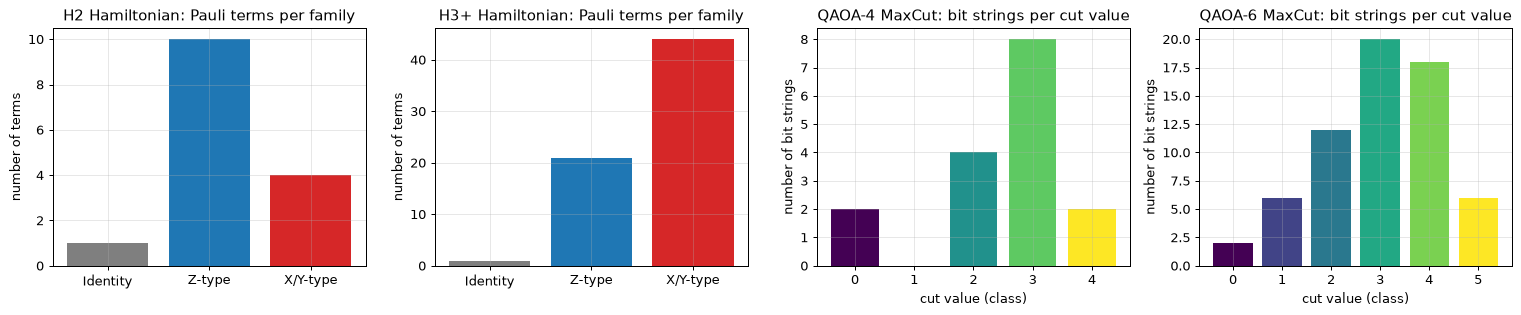

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (mol, h) in zip(axes[:2], HAM.items()):
    cnt = pd.Series([term_family(w) for w in h["words"]]).value_counts().reindex(FAMS).fillna(0)
    ax.bar(range(3), cnt.values, color=[FCOL[f] for f in FAMS]); ax.set_xticks(range(3)); ax.set_xticklabels(["Identity", "Z-type", "X/Y-type"])
    ax.set_title(f"{mol} Hamiltonian: Pauli terms per family"); ax.set_ylabel("number of terms")
for ax, (k, G) in zip(axes[2:], GRAPHS.items()):
    n = G.number_of_nodes(); bits = ((np.arange(2 ** n)[:, None] >> np.arange(n)[None, :]) & 1)
    cut = np.array([sum(b[i] != b[j] for i, j in G.edges()) for b in bits]); vc = pd.Series(cut).value_counts().sort_index()
    ax.bar(vc.index, vc.values, color=plt.cm.viridis(vc.index / max(vc.index.max(), 1))); ax.set_title(f"{k} MaxCut: bit strings per cut value")
    ax.set_xlabel("cut value (class)"); ax.set_ylabel("number of bit strings")
plt.tight_layout(); plt.show()

### Real observations in 2-D, coloured by ground-truth label

* Top row: every **Pauli term** of the molecular Hamiltonians, described by a one-hot code of its X/Y/Z letters per qubit plus its coefficient, projected with PCA (fitted on all terms); the colour is the term family. The papers' circuits use *no angle encoding of data* (the inputs are quantum states), so there is no second scatter in `[0, pi]`; the predefined input angles are drawn separately below.
* Bottom row: every **computational basis state** `|b>` of the molecular Hamiltonians (x: diagonal energy `<b|H|b>`, y: weight of `|b>` in the exact ground state, colour: particle number = Hamming weight) and every **bit string** of the MaxCut instances (PCA of the bit string, colour: cut value).

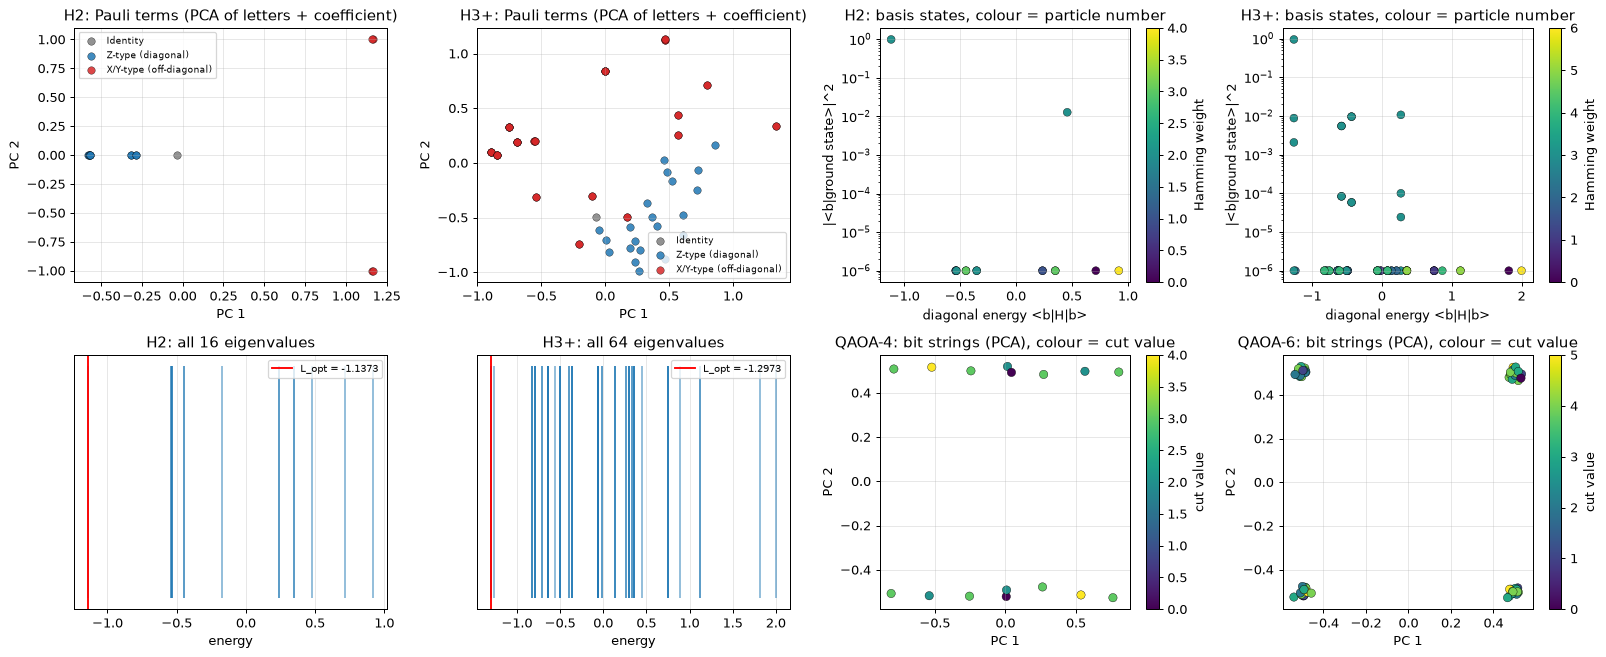

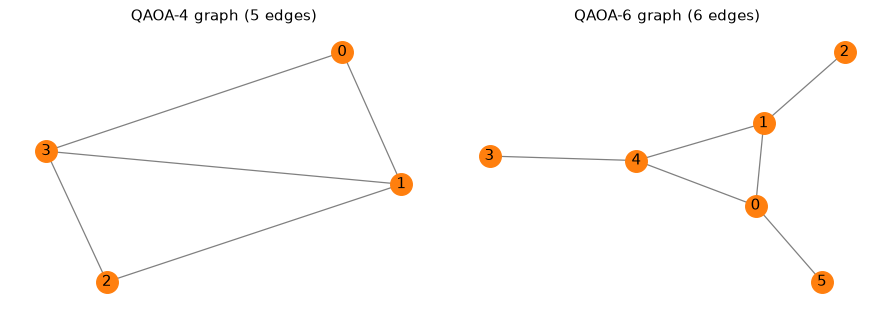

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.4))
for ax, (mol, h) in zip(axes[0, :2], HAM.items()):
    n = h["n"]; X = []
    for w, c in zip(h["words"], h["coeffs"]):
        v = np.zeros(3 * n + 1)
        for q, ch in enumerate(w):
            if ch != "I":
                v[3 * q + "XYZ".index(ch)] = 1
        v[-1] = c; X.append(v)
    Z = PCA(n_components=2, random_state=SEED).fit_transform(np.array(X)); fam = [term_family(w) for w in h["words"]]
    for f in FAMS:
        m = np.array([x == f for x in fam]); ax.scatter(Z[m, 0], Z[m, 1], c=FCOL[f], s=36, label=f, alpha=0.85, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{mol}: Pauli terms (PCA of letters + coefficient)"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=7)
for ax, (mol, h) in zip(axes[0, 2:], HAM.items()):
    n = h["n"]; Hm = dense_from_words(h["coeffs"], h["words"]); w, V = np.linalg.eigh(Hm)
    bits = ((np.arange(2 ** n)[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1); pn = bits.sum(1)
    sc = ax.scatter(np.real(np.diag(Hm)), np.abs(V[:, 0]) ** 2 + 1e-6, c=pn, cmap="viridis", s=40, edgecolor="k", linewidth=0.3)
    ax.set_yscale("log"); ax.set_xlabel("diagonal energy <b|H|b>"); ax.set_ylabel("|<b|ground state>|^2"); ax.set_title(f"{mol}: basis states, colour = particle number")
    plt.colorbar(sc, ax=ax, label="Hamming weight")
for ax, (mol, h) in zip(axes[1, :2], HAM.items()):
    n = h["n"]; Hm = dense_from_words(h["coeffs"], h["words"]); ev = np.linalg.eigvalsh(Hm)
    ax.vlines(ev, 0, 1, color="tab:blue", alpha=0.5); ax.axvline(ev[0], color="r", label="L_opt = %.4f" % ev[0]); ax.set_yticks([])
    ax.set_title(f"{mol}: all {2**n} eigenvalues"); ax.set_xlabel("energy"); ax.legend(fontsize=8)
for ax, (k, G) in zip(axes[1, 2:], GRAPHS.items()):
    n = G.number_of_nodes(); bits = ((np.arange(2 ** n)[:, None] >> np.arange(n)[None, :]) & 1)
    cut = np.array([sum(b[i] != b[j] for i, j in G.edges()) for b in bits])
    Z = PCA(n_components=2, random_state=SEED).fit_transform(bits.astype(float)); Z = Z + 0.02 * np.random.default_rng(SEED).normal(size=Z.shape)
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=cut, cmap="viridis", s=45, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{k}: bit strings (PCA), colour = cut value"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.colorbar(sc, ax=ax, label="cut value")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (k, G) in zip(axes, GRAPHS.items()):
    nx.draw_networkx(G, ax=ax, node_color="tab:orange", with_labels=True, edge_color="gray"); ax.set_title(f"{k} graph ({G.number_of_edges()} edges)"); ax.grid(False); ax.axis("off")
plt.tight_layout(); plt.show()

### The secret watermark inputs

A watermark group is `(rho_pre, M_pre, L_pre)`. The scatter shows the angles `(a_q, b_q)` of the predefined product-state inputs `RZ(b) RY(a) |0>` of 200 random groups next to the base input (`a = b = 0`), i.e. how far the secret inputs are from the normal one, and a histogram of the spectral range of the random observables `M_pre` against the target `L_pre`.

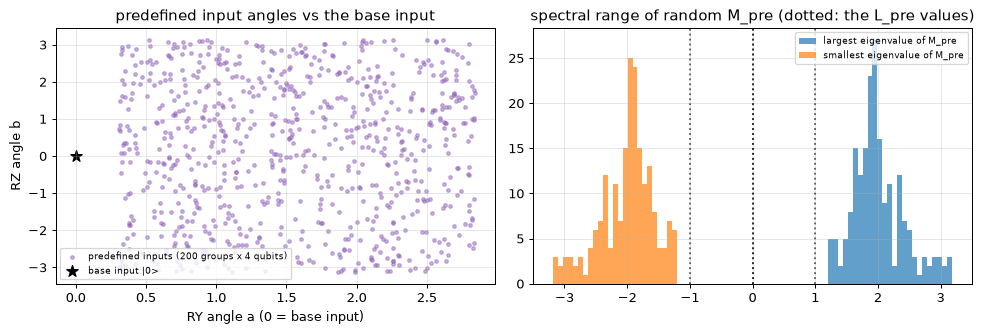

In [12]:
b0 = BENCH["VQE-H2"]; rr = np.random.default_rng(SEED + 1)
cfgs = [WMConfig(b0, rr) for _ in range(200)]
A = np.concatenate([c.a for c in cfgs]); Bn = np.concatenate([c.b for c in cfgs])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(A, Bn, s=8, alpha=0.5, c="tab:purple", label="predefined inputs (200 groups x 4 qubits)")
ax[0].scatter([0], [0], c="k", s=90, marker="*", label="base input |0>"); ax[0].set_xlabel("RY angle a (0 = base input)"); ax[0].set_ylabel("RZ angle b"); ax[0].legend(fontsize=7)
ax[0].set_title("predefined input angles vs the base input")
ev = [np.linalg.eigvalsh(c.M.numpy()) for c in cfgs]
ax[1].hist([e[-1] for e in ev], bins=25, alpha=0.7, label="largest eigenvalue of M_pre"); ax[1].hist([e[0] for e in ev], bins=25, alpha=0.7, label="smallest eigenvalue of M_pre")
for k, v in L_PRE.items():
    ax[1].axvline(v, color="k", ls=":", alpha=0.6)
ax[1].set_title("spectral range of random M_pre (dotted: the L_pre values)"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

For each distinct architecture the cell draws the circuit that is actually executed: the **PennyLane QNode** built from the gate list (the object whose output is asserted equal to the training simulator in section 3) and, for the watermark-extraction setting, the **Qiskit circuit** with the secret input preparation in front. Parameters are drawn with random values (the architecture does not depend on them). The printed table gives qubits, depth, trainable parameters and gate counts. Assumptions where the paper is silent: the VQE entangler is a ring of CNOTs; the H3+ circuit has 60 instead of 72 one-qubit gates; QAOA uses one free angle per `RZ` of every `CX RZ CX` block and per `RX`, with the Hadamard layer included in the circuit (so `|0...0>` as base input gives `|+...+>`).

Matplotlib is building the font cache; this may take a moment.


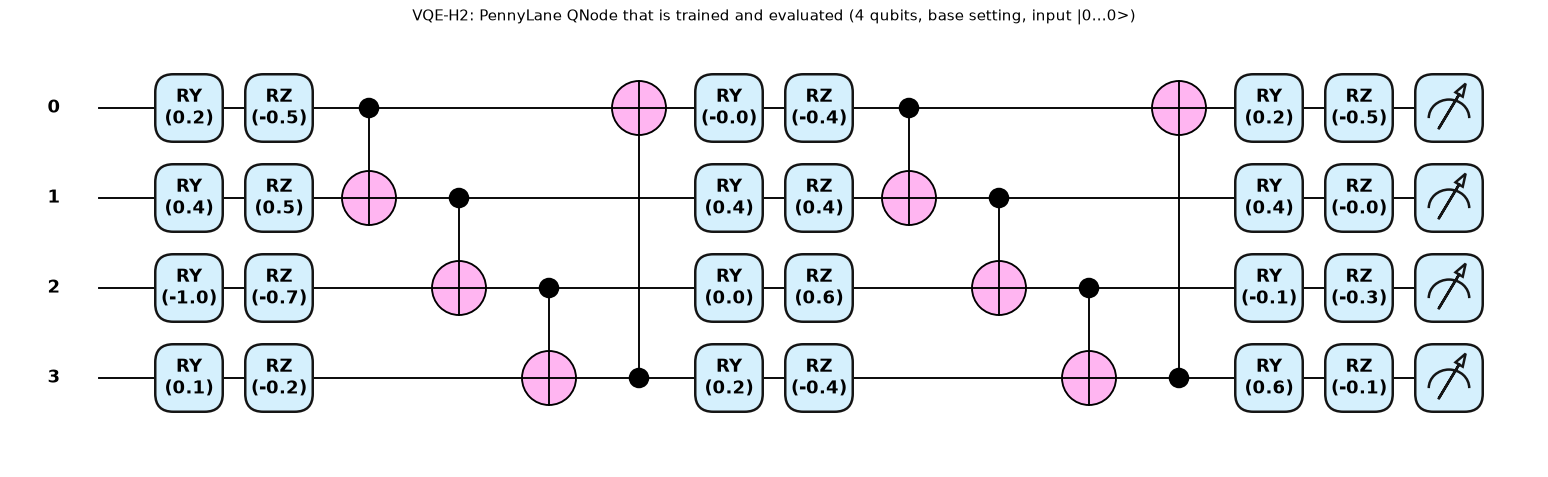

Matplotlib is building the font cache; this may take a moment.


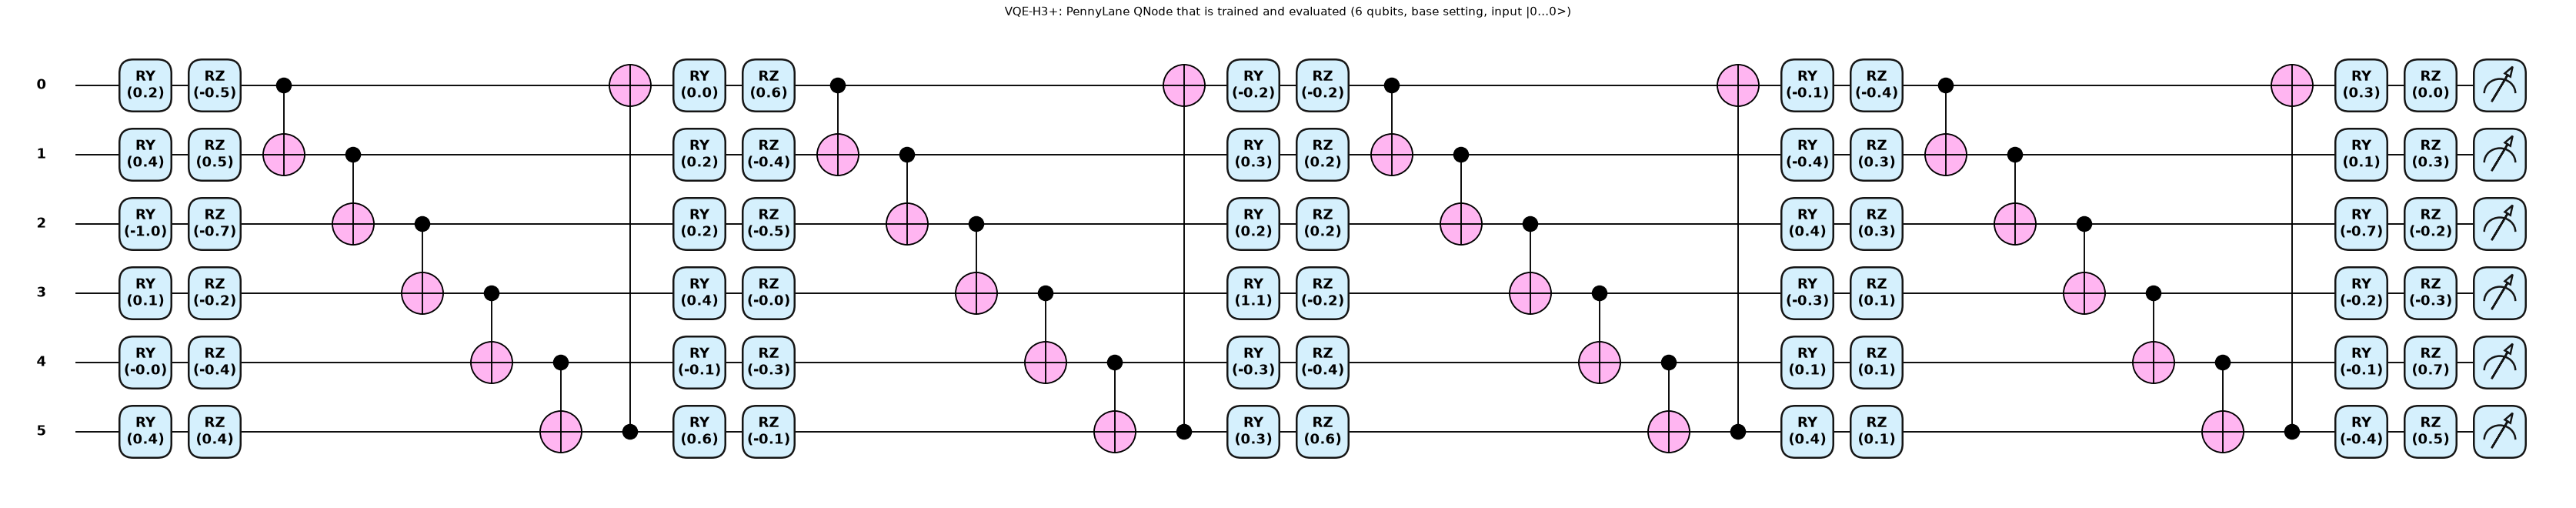

Matplotlib is building the font cache; this may take a moment.


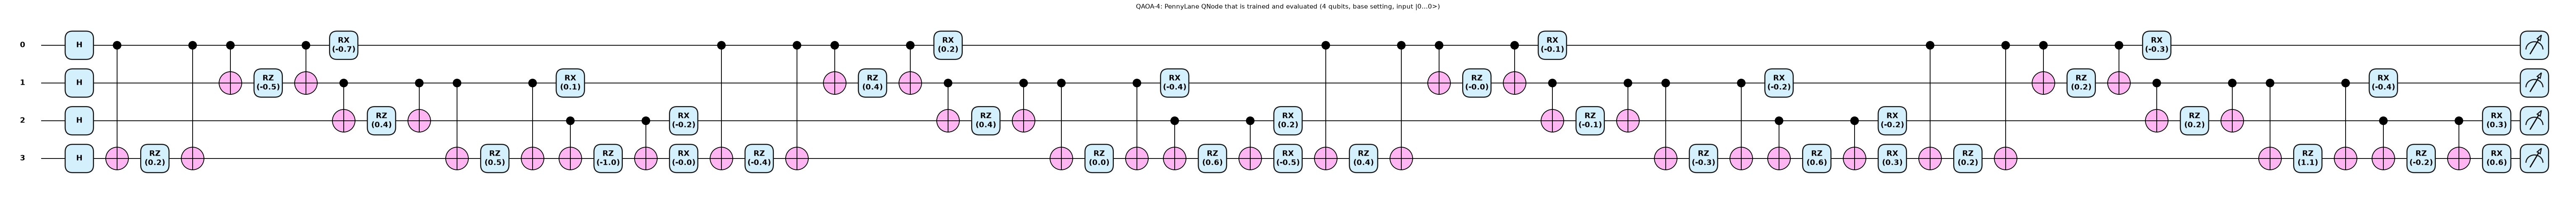

Matplotlib is building the font cache; this may take a moment.


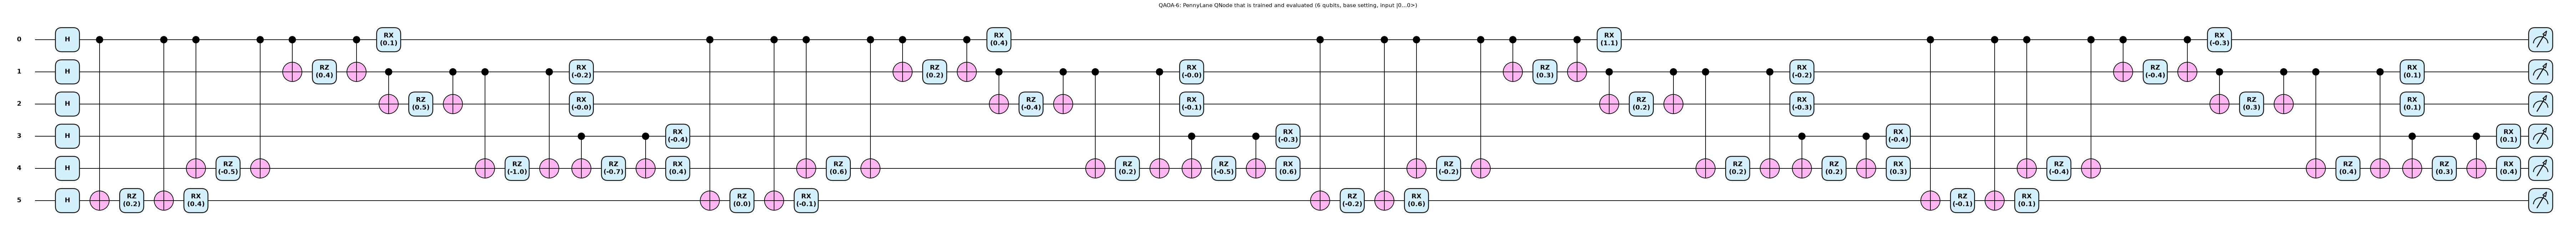

,architecture,qubits,depth,trainable_params,gates
0,VQE-H2,4,14,24,"{'ry': 12, 'rz': 12, 'cx': 8}"
1,VQE-H3+,6,34,60,"{'ry': 30, 'rz': 30, 'cx': 24}"
2,QAOA-4,4,65,36,"{'cx': 40, 'rz': 20, 'rx': 16, 'h': 4}"
3,QAOA-6,6,68,48,"{'cx': 48, 'rz': 24, 'rx': 24, 'h': 6}"


In [13]:
rows = []
for name, b in BENCH.items():
    th = np.random.default_rng(SEED).normal(0, 0.5, b.ans.n_params)
    qn = pennylane_qnode(b)
    fig, ax = qml.draw_mpl(qn, decimals=1, style="pennylane")(th)
    fig.suptitle(f"{name}: PennyLane QNode that is trained and evaluated ({b.n} qubits, base setting, input |0...0>)", y=1.02)
    plt.show()
    qc = qiskit_circuit(b, th); tq0 = qc
    rows.append(dict(architecture=name, qubits=b.n, depth=qc.depth(), trainable_params=b.ans.n_params, gates=dict(qc.count_ops())))
display(pd.DataFrame(rows))

watermark-extraction circuit of VQE-H2: qubits = 4 | depth = 16 | trainable parameters = 24 | fixed preparation gates = 8 | observable M_pre = {'IIZI': np.float64(0.97), 'IYII': np.float64(0.95), 'IYZI': np.float64(0.93), 'ZIXI': np.float64(0.36)}


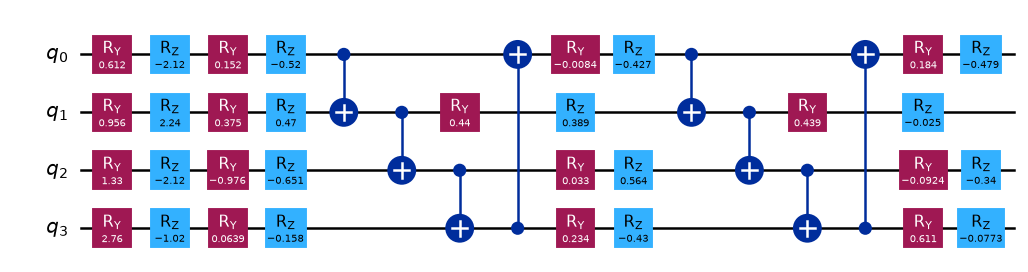

In [14]:
# The watermark-extraction setting: predefined input preparation (RY, RZ per qubit) in front of the same VQC; Qiskit drawing of VQE-H2
b = BENCH["VQE-H2"]; th = np.random.default_rng(SEED).normal(0, 0.5, b.ans.n_params)
wm_demo = WMConfig(b, np.random.default_rng(SEED + 2))
qc_w = qiskit_circuit(b, th, wm_demo)
print("watermark-extraction circuit of VQE-H2: qubits =", qc_w.num_qubits, "| depth =", qc_w.depth(), "| trainable parameters =", b.ans.n_params,
      "| fixed preparation gates =", 2 * b.n, "| observable M_pre =", dict(zip(wm_demo.words, np.round(wm_demo.coeffs, 2))))
display(qc_w.draw("mpl", fold=40))
# the circuit is compiled for a device exactly as in the paper (Qiskit optimisation level 3); the compiled version is drawn in section 7

## 3. Do the three implementations agree?

The training simulator (PyTorch), the PennyLane QNode and the Qiskit circuit are built from the same gate list. Before any result is trusted the next cell evaluates all three on random parameters, in the base setting (input `|0...0>`, Hamiltonian) and in the watermark-extraction setting (secret input, secret observable), and asserts agreement to 1e-9.

In [15]:
rng_eq = np.random.default_rng(SEED + 3)
rows = []
for name, b in BENCH.items():
    th = rng_eq.normal(0, 1.0, b.ans.n_params); wm = WMConfig(b, rng_eq); tt = torch.tensor(th)[None]
    base = [float(base_value(b, tt)[0]), ideal_value_qiskit(b, th), float(pennylane_qnode(b)(th))]
    wmv = [float(wm_value(b, tt, [wm])[0]), ideal_value_qiskit(b, th, wm), float(pennylane_qnode(b, True)(th, wm.a, wm.b, wm.words, wm.coeffs))]
    d1, d2 = np.ptp(base), np.ptp(wmv)
    assert d1 < 1e-9 and d2 < 1e-9, (name, base, wmv)
    rows.append(dict(benchmark=name, base_torch=base[0], base_qiskit=base[1], base_pennylane=base[2], max_diff_base=d1,
                     wm_torch=wmv[0], wm_qiskit=wmv[1], wm_pennylane=wmv[2], max_diff_wm=d2))
display(pd.DataFrame(rows).round(8))
print("OK: PyTorch simulator == PennyLane QNode == Qiskit circuit (base and watermark settings)")

,benchmark,base_torch,base_qiskit,base_pennylane,max_diff_base,wm_torch,wm_qiskit,wm_pennylane,max_diff_wm
0,VQE-H2,0.148846,0.148846,0.148846,0.0,0.197863,0.197863,0.197863,0.0
1,VQE-H3+,-0.170500,-0.170500,-0.170500,0.0,-0.295198,-0.295198,-0.295198,0.0
2,QAOA-4,-1.910124,-1.910124,-1.910124,0.0,-0.358659,-0.358659,-0.358659,0.0
3,QAOA-6,-2.746939,-2.746939,-2.746939,0.0,-0.034626,-0.034626,-0.034626,0.0


OK: PyTorch simulator == PennyLane QNode == Qiskit circuit (base and watermark settings)


## 4. Baseline: non-watermarked circuits (NW) and the learning rate

`NW` circuits are trained on the base task only. The loss is the energy (VQE) or the negative cut size (QAOA), so the **task GTD** of a trained circuit is `|loss - L_opt|` where `L_opt` is the exact lowest eigenvalue of the Hamiltonian matrix (the classical reference solution by exact diagonalisation). The paper trains for 300 epochs with Adam at a learning rate of 5e-3; the cell shows what that setting gives next to the learning rate used here.

In [16]:
def init_theta(K, P, seed):
    return torch.tensor(np.random.default_rng(seed).normal(0.0, 0.5, (K, P)))   # CHOICE: N(0, 0.5^2) initial angles

R = {}                    # all results per benchmark
rows = []
for bi, name in enumerate(BENCHMARKS):
    b = BENCH[name]; P = b.ans.n_params; t0 = time.time()
    th0 = init_theta(K_ARM, P, SEED + 100 * bi)
    th_nw, _, _ = train(b, th0, EPOCHS, LR, WEIGHT_DECAY)
    th_pp, _, _ = train(b, th0[:3], EPOCHS, PAPER_LR, WEIGHT_DECAY)
    g_nw = np.abs(base_value(b, th_nw) - b.l_opt); g_pp = np.abs(base_value(b, th_pp) - b.l_opt)
    R[name] = dict(init=th0, theta_nw=th_nw, nw_base_gtd=g_nw)
    rows.append(dict(benchmark=name, L_opt=round(b.l_opt, 4), epochs=EPOCHS, **{"task GTD lr=5e-3 (paper)": f"{g_pp.mean():.3f} +- {g_pp.std():.3f}",
                     f"task GTD lr={LR:g} (used)": f"{g_nw.mean():.4f} +- {g_nw.std():.4f}"}, seconds=round(time.time() - t0, 1)))
display(pd.DataFrame(rows))

,benchmark,L_opt,epochs,task GTD lr=5e-3 (paper),task GTD lr=0.05 (used),seconds
0,VQE-H2,-1.1373,300,0.160 +- 0.166,0.0021 +- 0.0062,49.5
1,VQE-H3+,-1.2973,300,0.095 +- 0.051,0.0125 +- 0.0052,92.9
2,QAOA-4,-4.0000,300,0.002 +- 0.003,0.0000 +- 0.0000,29.4
3,QAOA-6,-5.0000,300,0.004 +- 0.000,0.0000 +- 0.0000,59.2


## 5. BVQC training with and without grouping (Eq. 1-4, Fig. 4-6)

**Candidates.** A candidate group is a random predefined input, a random predefined observable and the target `L_pre` of Table V. A candidate is kept only if (i) `L_pre` lies inside the spectrum of `M_pre` with a margin, so that it can be reached, and (ii) a non-watermarked circuit misses `L_pre` by at least `MIN_SEP` (the paper's *unambiguity* requirement).

**Score (Eq. 3-4).** Starting from a trained NW circuit, `GROUP_STEPS` plain gradient steps are taken on the watermark loss `(f(theta, rho_pre, M_pre) - L_pre)^2` only. After each step the score `1 - |f_b(theta_{k+1}) - L_opt|^2 / |f_b(theta_k) - L_opt|^2` says whether the step also hurt the base task (negative) or not; the mean over steps is the candidate's score.

**Three arms** are then trained jointly with Eq. (1) from the same initial angles: `random` (no grouping, candidates in generation order), `POS` (the best-scored candidates, i.e. grouping) and `NEG` (the worst-scored ones). The paper's Fig. 5 compares POS and NEG training losses, Fig. 4 and Fig. 6 the base-task GTD without and with grouping.

In [17]:
def gen_candidates(b, rng, n_cand, theta_ref):
    out, tries = [], 0
    while len(out) < n_cand and tries < 200 * n_cand:
        tries += 1
        wm = WMConfig(b, rng); ev = np.linalg.eigvalsh(wm.M.numpy())
        if not (ev[0] + FEASIBLE_MARGIN < wm.l_pre < ev[-1] - FEASIBLE_MARGIN):
            continue
        if abs(wm_value(b, theta_ref[None], [wm])[0] - wm.l_pre) < MIN_SEP:
            continue
        out.append(wm)
    return out

def group_scores(b, wms, theta_ref, steps, lr):
    """Eq. (3)-(4): aggregated effect of watermark gradient steps on the base-task distance to L_opt."""
    C = len(wms); P_, M_, L_ = stack_wm(wms)
    th = theta_ref[None].repeat(C, 1).clone()
    d_prev = (base_value(b, th) - b.l_opt) ** 2
    agg = np.zeros(C)
    for k in range(steps):
        th = th.detach().requires_grad_(True)
        loss = ((b.energy(th, P_, M_) - L_) ** 2).sum()
        g, = torch.autograd.grad(loss, th)
        th = (th - lr * g).detach()
        d_new = (base_value(b, th) - b.l_opt) ** 2
        agg += 1.0 - d_new / (d_prev + 1e-12); d_prev = d_new
    return agg / steps

def summarise(b, th, wms):
    base = base_value(b, th); wmv = wm_value(b, th, wms)
    return dict(base=base, base_gtd=np.abs(base - b.l_opt), wm=wmv, wm_gtd=np.abs(wmv - np.array([w.l_pre for w in wms])))

for bi, name in enumerate(BENCHMARKS):
    b = BENCH[name]; r = R[name]; t0 = time.time(); rng = np.random.default_rng(SEED + 7 + bi)
    cands = gen_candidates(b, rng, N_CAND, r["theta_nw"][0])
    sc = group_scores(b, cands, r["theta_nw"][0], GROUP_STEPS, GROUP_LR)
    order = np.argsort(-sc)
    arms_idx = {"random": list(range(K_ARM)), "POS": [int(i) for i in order[:K_ARM]], "NEG": [int(i) for i in order[::-1][:K_ARM]]}
    wms = [cands[i] for a in ("random", "POS", "NEG") for i in arms_idx[a]]
    th0 = r["init"].repeat(3, 1)                                  # identical initial angles in the three arms
    th, hist, _ = train(b, th0, EPOCHS, LR, WEIGHT_DECAY, wms=wms, alpha=ALPHA, beta=BETA, record=10)
    res = summarise(b, th, wms)
    arm = {}
    for ai, a in enumerate(("random", "POS", "NEG")):
        sl = slice(ai * K_ARM, (ai + 1) * K_ARM)
        arm[a] = dict(theta=th[sl], wms=wms[sl], idx=arms_idx[a], curve=np.array([h[1][sl].mean() for h in hist]),
                      **{k: v[sl] for k, v in res.items()})
    epochs_rec = np.array([h[0] for h in hist])
    nw_wm = wm_value(b, r["theta_nw"], arm["POS"]["wms"])             # NW circuits probed with the POS watermark groups (paired)
    r.update(cands=cands, scores=sc, arms=arm, epochs_rec=epochs_rec, nw_wm_gtd_pos=np.abs(nw_wm - b.l_pre))
    print(f"{name}: {len(cands)} candidates, {int((sc > 0).sum())} with positive score, trained 3 x {K_ARM} circuits in {time.time()-t0:.0f} s")

rows = []
for name in BENCHMARKS:
    r = R[name]
    for a in ("random", "POS", "NEG"):
        d = r["arms"][a]
        rows.append(dict(benchmark=name, arm=a, final_base_loss=f"{d['base'].mean():.4f}", base_GTD=f"{d['base_gtd'].mean():.4f} +- {d['base_gtd'].std():.4f}",
                         watermark_GTD=f"{d['wm_gtd'].mean():.4f}", watermark_embedded=f"{(d['wm_gtd'] <= TAU).mean():.0%}", mean_score=round(float(r['scores'][d['idx']].mean()), 3)))
    rows.append(dict(benchmark=name, arm="NW (no watermark)", final_base_loss=f"{base_value(BENCH[name], r['theta_nw']).mean():.4f}",
                     base_GTD=f"{r['nw_base_gtd'].mean():.4f} +- {r['nw_base_gtd'].std():.4f}", watermark_GTD=f"{r['nw_wm_gtd_pos'].mean():.4f}", watermark_embedded="-", mean_score="-"))
display(pd.DataFrame(rows))

VQE-H2: 60 candidates, 0 with positive score, trained 3 x 10 circuits in 29 s


VQE-H3+: 60 candidates, 0 with positive score, trained 3 x 10 circuits in 315 s


QAOA-4: 60 candidates, 0 with positive score, trained 3 x 10 circuits in 27 s


QAOA-6: 60 candidates, 0 with positive score, trained 3 x 10 circuits in 195 s


,benchmark,arm,final_base_loss,base_GTD,watermark_GTD,watermark_embedded,mean_score
0,VQE-H2,random,-1.1328,0.0044 +- 0.0089,0.0018,100%,-0.16
1,VQE-H2,POS,-1.1331,0.0042 +- 0.0082,0.0002,100%,-0.044
2,VQE-H2,NEG,-1.1326,0.0047 +- 0.0080,0.0011,100%,-0.204
3,VQE-H2,NW (no watermark),-1.1352,0.0021 +- 0.0062,0.3342,-,-
4,VQE-H3+,random,-1.2855,0.0118 +- 0.0042,0.0008,100%,-0.143
5,VQE-H3+,POS,-1.2854,0.0119 +- 0.0061,0.0007,100%,-0.095
6,VQE-H3+,NEG,-1.2866,0.0107 +- 0.0050,0.0006,100%,-0.289
7,VQE-H3+,NW (no watermark),-1.2847,0.0125 +- 0.0052,0.1575,-,-
8,QAOA-4,random,-3.9999,0.0001 +- 0.0002,0.0013,100%,-18473175.341
9,QAOA-4,POS,-4.0000,0.0000 +- 0.0000,0.0002,100%,-503453.168


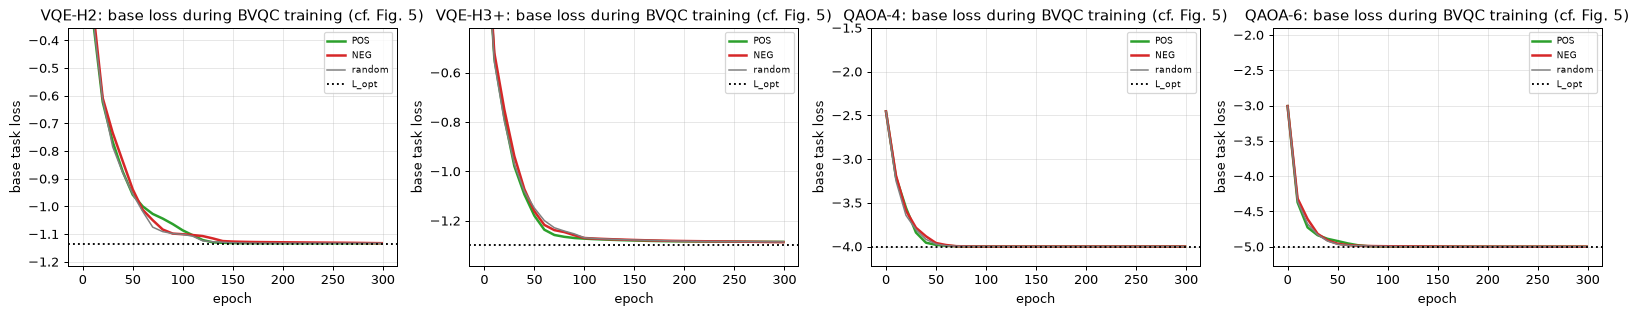

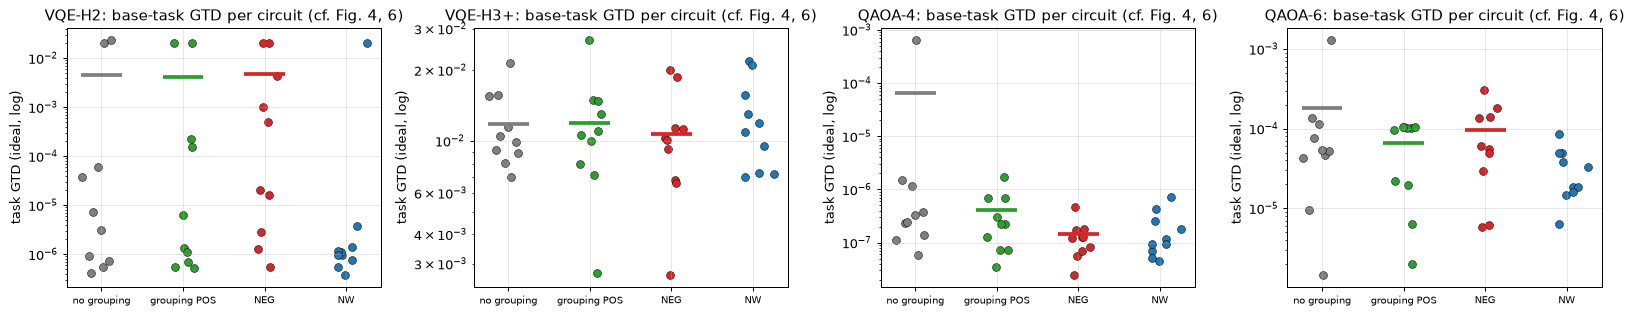

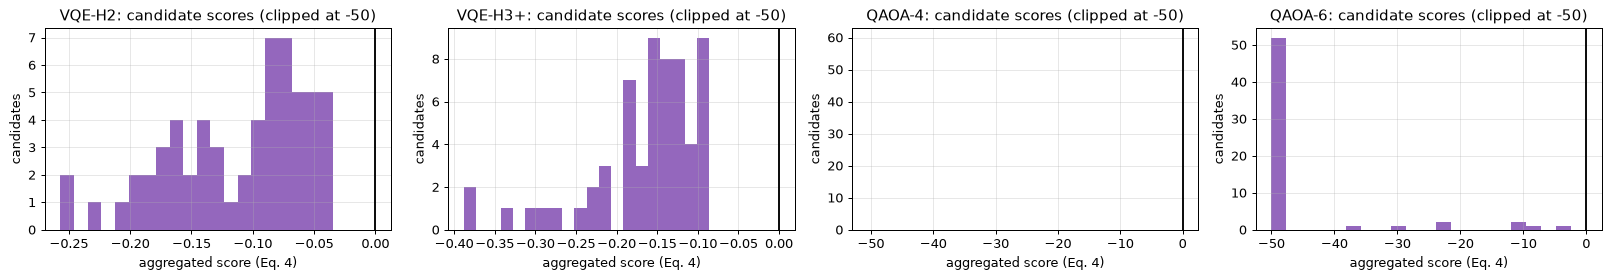

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, name in zip(axes, BENCHMARKS):
    r = R[name]
    for a, c in (("POS", "tab:green"), ("NEG", "tab:red"), ("random", "tab:gray")):
        ax.plot(r["epochs_rec"], r["arms"][a]["curve"], color=c, label=a, lw=2 if a != "random" else 1.2)
    ax.axhline(BENCH[name].l_opt, color="k", ls=":", label="L_opt"); ax.set_title(f"{name}: base loss during BVQC training (cf. Fig. 5)")
    ax.set_xlabel("epoch"); ax.set_ylabel("base task loss"); ax.legend(fontsize=7)
    lo = BENCH[name].l_opt; ax.set_ylim(lo - 0.05 * abs(lo) - 0.02, lo + 0.6 * abs(lo) + 0.1)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, name in zip(axes, BENCHMARKS):
    r = R[name]; rr_ = np.random.default_rng(SEED)
    for i, (a, c) in enumerate((("random", "tab:gray"), ("POS", "tab:green"), ("NEG", "tab:red"))):
        v = r["arms"][a]["base_gtd"]; ax.scatter(i + 0.12 * rr_.normal(size=len(v)), v, c=c, s=40, edgecolor="k", linewidth=0.4); ax.hlines(v.mean(), i - 0.25, i + 0.25, color=c, lw=3)
    ax.scatter(3 + 0.12 * rr_.normal(size=len(r["nw_base_gtd"])), r["nw_base_gtd"], c="tab:blue", s=40, edgecolor="k", linewidth=0.4)
    ax.set_xticks(range(4)); ax.set_xticklabels(["no grouping", "grouping POS", "NEG", "NW"], fontsize=8); ax.set_yscale("log")
    ax.set_title(f"{name}: base-task GTD per circuit (cf. Fig. 4, 6)"); ax.set_ylabel("task GTD (ideal, log)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.2))
for ax, name in zip(axes, BENCHMARKS):
    sc = R[name]["scores"]; ax.hist(np.clip(sc, -50, 1), bins=20, color="tab:purple"); ax.axvline(0, color="k")
    ax.set_title(f"{name}: candidate scores (clipped at -50)"); ax.set_xlabel("aggregated score (Eq. 4)"); ax.set_ylabel("candidates")
plt.tight_layout(); plt.show()

## 6. Noisy devices with zero-noise extrapolation (Table V, Fig. 7 and 9)

The paper executes the compiled circuits on IBM Kolkata and Cairo and applies ZNE. Here the two devices are simulated by Qiskit Aer from the stored calibration data of `FakeKolkataV2` and `FakeHanoiV2` (the shipped `FakeCairoV2` snapshot cannot be compiled to, so Hanoi stands in for Cairo; its mean CNOT error is 4x Kolkata's because of a few bad links) (gate errors, relaxation; a density-matrix simulation of the transpiled circuit, exact expectation values). The circuits are compiled at optimisation level 3 for the device, folded to noise scales 1, 3, 5 (global unitary folding `U (U^dagger U)^k`) and extrapolated to zero noise with Richardson extrapolation. For every benchmark the first `N_NOISY` successfully watermarked POS circuits are compared with their paired NW circuit (same initial angles); NW circuits are probed with the same secret group as their BVQC partner, which gives the "NW watermark GTD" column of Table V.

In [19]:
DEVICES = {"Kolkata": NoisyDevice(FakeKolkataV2(), "Kolkata"), "Hanoi": NoisyDevice(FakeHanoiV2(), "Hanoi")}   # Hanoi replaces Cairo, see the table in the introduction

def device_eval(dev, b, theta, wm=None, seed=0):
    qc = qiskit_circuit(b, theta, wm); tq = dev.compile(qc, seed=seed)
    words, coeffs = (wm.words, wm.coeffs) if wm is not None else (b.words, b.coeffs)
    vals, zne = dev.expval(tq, words, coeffs, ZNE_SCALES)
    target = wm.l_pre if wm is not None else b.l_opt
    return dict(raw=vals[0], zne=zne, gtd_raw=abs(vals[0] - target), gtd=abs(zne - target)), tq

# deployed circuits: best base GTD among the POS circuits whose watermark was embedded
for name in BENCHMARKS:
    r = R[name]; d = r["arms"]["POS"]
    ok = [j for j in np.argsort(d["base_gtd"]) if d["wm_gtd"][j] <= TAU]
    if len(ok) < N_NOISY:
        ok += [j for j in np.argsort(d["wm_gtd"]) if j not in ok]
    r["deployed"] = [int(j) for j in ok[:max(N_NOISY, N_ATTACK)]]

recs = []
for dname, dev in DEVICES.items():
    for name in BENCHMARKS:
        b = BENCH[name]; r = R[name]; d = r["arms"]["POS"]; t0 = time.time()
        for j in r["deployed"][:N_NOISY]:
            # the paired NW circuit has the same initial angles (position j in the arm)
            th_b = d["theta"][j].numpy(); th_n = r["theta_nw"][j].numpy(); wm = d["wms"][j]
            e_bb, _ = device_eval(dev, b, th_b); e_bw, _ = device_eval(dev, b, th_b, wm)
            e_nb, _ = device_eval(dev, b, th_n); e_nw, _ = device_eval(dev, b, th_n, wm)
            recs.append(dict(device=dname, benchmark=name, model=j, NW_base=e_nb["gtd"], BVQC_base=e_bb["gtd"], NW_wm=e_nw["gtd"], BVQC_wm=e_bw["gtd"],
                             NW_base_noZNE=e_nb["gtd_raw"], BVQC_base_noZNE=e_bb["gtd_raw"], NW_wm_noZNE=e_nw["gtd_raw"], BVQC_wm_noZNE=e_bw["gtd_raw"]))
        print(f"{dname:8s} {name:8s} done in {time.time()-t0:.0f} s", flush=True)
NOISY = pd.DataFrame(recs)
tab5 = NOISY.groupby(["benchmark", "device"])[["NW_base", "BVQC_base", "NW_wm", "BVQC_wm"]].mean().round(3)
tab5 = tab5.reindex(BENCHMARKS, level=0)
tab5.columns = ["base GTD NW", "base GTD BVQC", "watermark GTD NW", "watermark GTD BVQC"]
display(tab5)
avg = NOISY.groupby("device")[["NW_base", "BVQC_base", "NW_wm", "BVQC_wm"]].mean().round(4)
avg.columns = ["base GTD NW", "base GTD BVQC", "watermark GTD NW", "watermark GTD BVQC"]
print("Average over benchmarks (this notebook, simulated devices + ZNE):"); display(avg)
print("Without ZNE (scale 1 only):"); display(NOISY.groupby("device")[["NW_base_noZNE", "BVQC_base_noZNE", "NW_wm_noZNE", "BVQC_wm_noZNE"]].mean().round(4))

Kolkata  VQE-H2   done in 81 s


Kolkata  VQE-H3+  done in 141 s


Kolkata  QAOA-4   done in 74 s


Kolkata  QAOA-6   done in 98 s


Hanoi    VQE-H2   done in 73 s


...

base GTD NW  base GTD BVQC  watermark GTD NW  \
benchmark device                                                  
VQE-H2    Hanoi          0.001          0.001             0.410   
          Kolkata        0.003          0.003             0.409   
VQE-H3+   Hanoi          0.087          0.089             0.123   
          Kolkata        0.131          0.134             0.118   
QAOA-4    Hanoi          0.072          0.067             1.005   
          Kolkata        0.145          0.142             1.005   
QAOA-6    Hanoi          0.051          0.040             0.507   
          Kolkata        0.070          0.065             0.517   

                   watermark GTD BVQC  
benchmark device                       
VQE-H2    Hanoi                 0.001  
          Kolkata               0.002  
VQE-H3+   Hanoi                 0.003  
          Kolkata               0.005  
QAOA-4    Hanoi                 0.033  
          Kolkata               0.073  
QAOA-6    Hanoi                 0.015  
          Kolkata               0.033

Average over benchmarks (this notebook, simulated devices + ZNE):


,base GTD NW,base GTD BVQC,watermark GTD NW,watermark GTD BVQC
device,,,,
Hanoi,0.0525,0.0494,0.5113,0.0128
Kolkata,0.0873,0.0859,0.5123,0.0284


Without ZNE (scale 1 only):


,NW_base_noZNE,BVQC_base_noZNE,NW_wm_noZNE,BVQC_wm_noZNE
device,,,,
Hanoi,0.3245,0.3182,0.5075,0.1003
Kolkata,0.3858,0.3843,0.5110,0.1337


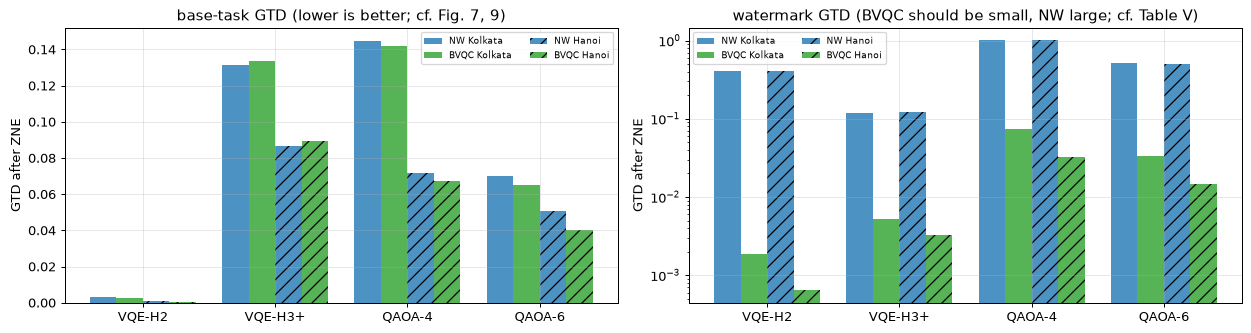

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8)); w = 0.2; x = np.arange(len(BENCHMARKS))
for k, (dname, hatch) in enumerate((("Kolkata", None), ("Hanoi", "//"))):
    sub = NOISY[NOISY.device == dname].groupby("benchmark")[["NW_base", "BVQC_base", "NW_wm", "BVQC_wm"]].mean().reindex(BENCHMARKS)
    axes[0].bar(x + (k * 2 - 1.5) * w + w / 2 * 0, sub["NW_base"], w, label=f"NW {dname}", color="tab:blue", hatch=hatch, alpha=0.8)
    axes[0].bar(x + (k * 2 - 0.5) * w, sub["BVQC_base"], w, label=f"BVQC {dname}", color="tab:green", hatch=hatch, alpha=0.8)
    axes[1].bar(x + (k * 2 - 1.5) * w, sub["NW_wm"], w, label=f"NW {dname}", color="tab:blue", hatch=hatch, alpha=0.8)
    axes[1].bar(x + (k * 2 - 0.5) * w, sub["BVQC_wm"], w, label=f"BVQC {dname}", color="tab:green", hatch=hatch, alpha=0.8)
for ax, t in zip(axes, ("base-task GTD (lower is better; cf. Fig. 7, 9)", "watermark GTD (BVQC should be small, NW large; cf. Table V)")):
    ax.set_xticks(x); ax.set_xticklabels(BENCHMARKS); ax.set_title(t); ax.legend(fontsize=7, ncol=2); ax.set_ylabel("GTD after ZNE")
axes[1].set_yscale("log"); plt.tight_layout(); plt.show()

## 7. Re-compilation (Table III, Fig. 8)

The thief re-compiles the published circuit. Two experiments mirror the paper:

1. **Structure and GTD before / after re-compilation** (Table III): compile at level 3 with transpiler seed 0 ("before") and seed 7 ("after") for Kolkata, and report depth, one- and two-qubit gate counts, the initial qubit mapping and the noisy task GTD of the NW and the BVQC circuit.
2. **Invariance of the watermark**: compile the same circuit with 7 different settings (optimisation levels 1-3 times two seeds on Kolkata, plus level 3 on Hanoi) and compare the *noise-free* expectation values of the compiled circuits with the original ones. If the watermark lives in the unitary, the base value and the watermark value of the compiled circuits are identical. A prior-art watermark in the gate structure would not survive this (its PPA rises in Table I and Fig. 8). The MS baseline is not public, so only the BVQC side can be measured here.

,benchmark,circuit,depth,one_qubit,cnot,init_mapping,base_GTD
0,VQE-H2,NW,37 -> 37,48 -> 48,17 -> 17,"[22, 25, 26, 24] -> [22, 25, 26, 24]",0.003 -> 0.003
1,VQE-H2,BVQC,37 -> 37,48 -> 48,17 -> 17,"[22, 25, 26, 24] -> [22, 25, 26, 24]",0.003 -> 0.003
2,VQE-H3+,NW,123 -> 123,152 -> 152,70 -> 70,"[22, 25, 24, 21, 23, 26] -> [22, 25, 24, 21, 2...",0.118 -> 0.118
3,VQE-H3+,BVQC,123 -> 123,151 -> 151,70 -> 70,"[22, 25, 24, 21, 23, 26] -> [22, 25, 24, 21, 2...",0.149 -> 0.149
4,QAOA-4,NW,123 -> 127,150 -> 145,56 -> 56,"[26, 24, 22, 25] -> [25, 22, 26, 24]",0.173 -> 0.155
5,QAOA-4,BVQC,122 -> 127,150 -> 147,56 -> 56,"[26, 24, 22, 25] -> [25, 22, 26, 24]",0.154 -> 0.143
6,QAOA-6,NW,110 -> 110,187 -> 187,63 -> 63,"[24, 22, 26, 19, 25, 23] -> [24, 22, 26, 19, 2...",0.071 -> 0.071
7,QAOA-6,BVQC,110 -> 110,187 -> 187,63 -> 63,"[24, 22, 26, 19, 25, 23] -> [24, 22, 26, 19, 2...",0.075 -> 0.075


Compiled BVQC circuit of VQE-H2 on (simulated) Kolkata, level 3, seed 0:


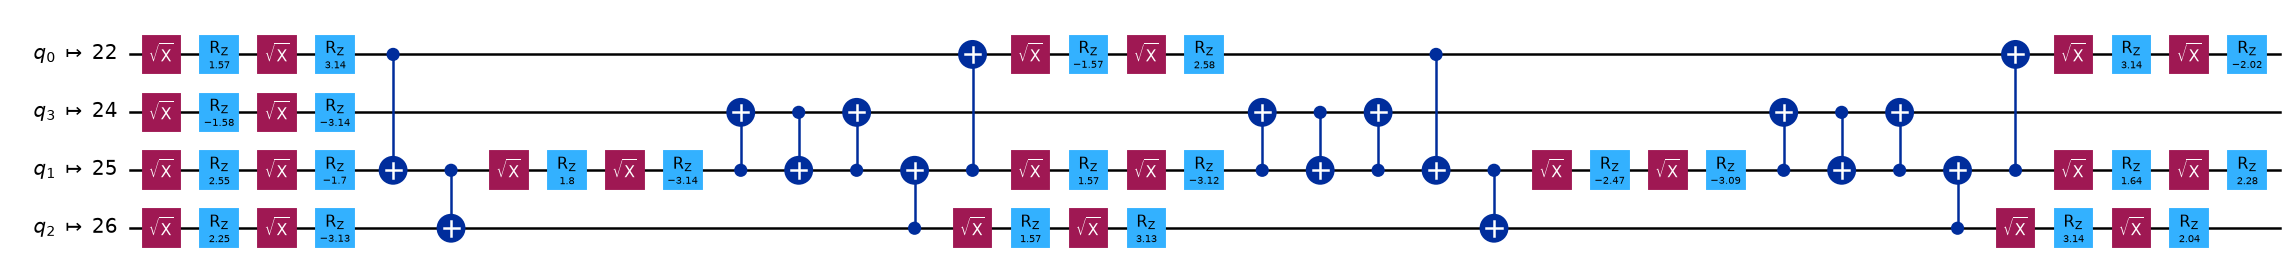

In [21]:
def structure(tq, n):
    ops = tq.count_ops(); twoq = sum(v for k_, v in ops.items() if k_ in ("cx", "ecr", "cz"))
    oneq = sum(v for k_, v in ops.items() if k_ in ("rz", "sx", "x", "id"))
    return dict(depth=tq.depth(), one_qubit=oneq, two_qubit=twoq, mapping=list(tq.layout.initial_index_layout(filter_ancillas=True)[:n]))

dev = DEVICES["Kolkata"]; rows = []; tq_show = None; STRUCT = []
for name in BENCHMARKS:
    b = BENCH[name]; r = R[name]; d = r["arms"]["POS"]; j = r["deployed"][0]
    th_b = d["theta"][j].numpy(); th_n = r["theta_nw"][j].numpy(); wm = d["wms"][j]
    for label, th in (("NW", th_n), ("BVQC", th_b)):
        out = {}
        for when, seed in (("before", 0), ("after", 7)):
            e, tq = device_eval(dev, b, th, None, seed=seed); s = structure(tq, b.n); out[when] = (e["gtd"], s)
            if label == "BVQC" and name == "VQE-H2" and when == "before":
                tq_show = tq
        STRUCT.append(dict(benchmark=name, circuit=label, same=out["before"][1] == out["after"][1], dgtd=abs(out["before"][0] - out["after"][0])))
        rows.append(dict(benchmark=name, circuit=label, depth=f"{out['before'][1]['depth']} -> {out['after'][1]['depth']}",
                         one_qubit=f"{out['before'][1]['one_qubit']} -> {out['after'][1]['one_qubit']}", cnot=f"{out['before'][1]['two_qubit']} -> {out['after'][1]['two_qubit']}",
                         init_mapping=f"{out['before'][1]['mapping']} -> {out['after'][1]['mapping']}", base_GTD=f"{out['before'][0]:.3f} -> {out['after'][0]:.3f}"))
display(pd.DataFrame(rows))
print("Compiled BVQC circuit of VQE-H2 on (simulated) Kolkata, level 3, seed 0:")
display(tq_show.draw("mpl", idle_wires=False, fold=70))

In [22]:
VARIANTS = [("Kolkata", lvl, s) for lvl in (1, 2, 3) for s in (0, 1)] + [("Hanoi", 3, 0)]
rows = []; maxdiff = {}
for name in BENCHMARKS:
    b = BENCH[name]; r = R[name]; d = r["arms"]["POS"]; j = r["deployed"][0]; th = d["theta"][j].numpy(); wm = d["wms"][j]
    ref_b = float(base_value(b, torch.tensor(th)[None])[0]); ref_w = float(wm_value(b, torch.tensor(th)[None], [wm])[0])
    db, dw = [], []
    for dn, lvl, s in VARIANTS:
        tqb = DEVICES[dn].compile(qiskit_circuit(b, th), seed=s, level=lvl); tqw = DEVICES[dn].compile(qiskit_circuit(b, th, wm), seed=s, level=lvl)
        db.append(abs(ideal_expval_compiled(tqb, b.words, b.coeffs) - ref_b)); dw.append(abs(ideal_expval_compiled(tqw, wm.words, wm.coeffs) - ref_w))
    maxdiff[name] = (max(db), max(dw))
    rows.append(dict(benchmark=name, original_base_value=round(ref_b, 6), original_watermark_value=round(ref_w, 6), L_pre=wm.l_pre,
                     max_change_base_after_recompile=f"{max(db):.1e}", max_change_watermark_after_recompile=f"{max(dw):.1e}"))
display(pd.DataFrame(rows))
assert all(v[1] < 1e-6 for v in maxdiff.values()), maxdiff
print("The watermark value is invariant under all 7 re-compilations (noise-free, change below 1e-6).")

,benchmark,original_base_value,original_watermark_value,L_pre,max_change_base_after_recompile,max_change_watermark_after_recompile
0,VQE-H2,-1.137263,-0.000016,0.0,4.4e-16,3.4e-16
1,VQE-H3+,-1.294536,0.002409,0.0,5.8e-15,2.2e-15
2,QAOA-4,-4.000000,1.000044,1.0,3.2e-14,6.9e-15
3,QAOA-6,-4.999998,-0.999643,-1.0,3.5e-14,7.2e-15


The watermark value is invariant under all 7 re-compilations (noise-free, change below 1e-6).


## 8. Ownership verification: true and false positives

The owner shows the secret group `(rho_pre, M_pre, L_pre)`; ownership is accepted when `|f(theta, rho_pre, M_pre) - L_pre| <= TAU`. The cell measures

* **true-positive rate**: watermarked circuits (random / POS / NEG arms) checked with their own group;
* **false-positive rate against innocent circuits**: independently trained NW circuits, and random-angle circuits, checked with every candidate group;
* **wrong-key rate**: a watermarked circuit checked with a group that belongs to *another* watermarked circuit.

In [23]:
rows = []; VER = {}
for name in BENCHMARKS:
    b = BENCH[name]; r = R[name]; P = b.ans.n_params
    tp = np.concatenate([(r["arms"][a]["wm_gtd"] <= TAU) for a in ("random", "POS", "NEG")])
    nw_all = np.array([(np.abs(wm_value(b, r["theta_nw"], [w] * len(r["theta_nw"])) - w.l_pre) <= TAU) for w in r["cands"]])
    rnd = torch.tensor(np.random.default_rng(SEED + 5).uniform(-np.pi, np.pi, (200, P)))
    rnd_all = np.array([(np.abs(wm_value(b, rnd, [w] * 200) - w.l_pre) <= TAU) for w in r["cands"]])
    wrong = []
    allm = [(r["arms"][a]["theta"][j], r["arms"][a]["wms"][j]) for a in ("random", "POS", "NEG") for j in range(K_ARM)]
    for i, (th, _) in enumerate(allm):
        for k, (_, w) in enumerate(allm):
            if i != k:
                wrong.append(abs(wm_value(b, th[None], [w])[0] - w.l_pre) <= TAU)
    VER[name] = dict(tpr=tp.mean(), fpr_nw=nw_all.mean(), fpr_random=rnd_all.mean(), wrong=np.mean(wrong))
    rows.append(dict(benchmark=name, TPR_own_key=f"{tp.mean():.2f}", FPR_NW_circuits=f"{nw_all.mean():.3f}", FPR_random_circuits=f"{rnd_all.mean():.3f}", accepted_with_wrong_key=f"{np.mean(wrong):.3f}"))
display(pd.DataFrame(rows))

,benchmark,TPR_own_key,FPR_NW_circuits,FPR_random_circuits,accepted_with_wrong_key
0,VQE-H2,1.00,0.162,0.231,0.171
1,VQE-H3+,1.00,0.338,0.435,0.338
2,QAOA-4,1.00,0.015,0.008,0.014
3,QAOA-6,1.00,0.003,0.007,0.024


## 9. Removal attacks and a smoothing variant (Sec. IV-E; extension)

The paper only states in words that fine-tuning is the most effective removal attack and that parameter smoothing [25] makes the watermark survive it. The cell turns this into an experiment on the deployed POS circuits:

* **fine-tune**: the attacker continues training on the base task with Adam (`FT_LR`) for several steps (the circuit already sits at the base optimum, so this alone barely moves it);
* **perturb + fine-tune**: the attacker first adds Gaussian noise (std 0.3) to all angles to push the circuit away from the watermark and then fine-tunes the base task back (the realistic removal attack: accuracy is restored);
* **pruning**: the fraction of angles closest to 0 (mod 2 pi) is set to 0;
* **parameter noise**: Gaussian noise on all angles without fine-tuning.

The **smoothed** variant trains the same circuits (same groups, same initial angles) with the watermark term evaluated at `theta + N(0, SMOOTH_SIGMA^2)`, a randomised-smoothing-style training (`# CHOICE`; the paper gives no detail). An attack *removes* the watermark when the watermark GTD exceeds `TAU`; a circuit is "still useful" when its base GTD stays within 0.05 of the original.

In [24]:
def wrap(th):
    return torch.atan2(torch.sin(th), torch.cos(th))

ATK = {}
t0 = time.time()
for bi, name in enumerate(BENCHMARKS):
    b = BENCH[name]; r = R[name]; d = r["arms"]["POS"]; sel = r["deployed"][:N_ATTACK]
    wms = [d["wms"][j] for j in sel]; th_plain = d["theta"][sel]
    th_s, _, _ = train(b, r["init"][sel], EPOCHS, LR, WEIGHT_DECAY, wms=wms, alpha=ALPHA, beta=BETA, smooth_sigma=SMOOTH_SIGMA, seed=SEED)
    out = {}
    for variant, th in (("plain", th_plain), ("smooth", th_s)):
        res = []
        base0 = base_value(b, th)
        res.append(("none", "-", th))
        # fine-tune and perturb + fine-tune: one batched run per attack, snapshots at ATTACK_STEPS
        _, _, snaps = train(b, th, max(ATTACK_STEPS), FT_LR, 0.0, snap=ATTACK_STEPS)
        for s in ATTACK_STEPS[1:]:
            res.append(("fine-tune", f"{s} steps", snaps[s]))
        gen = torch.Generator().manual_seed(SEED + 11)
        thp = th + 0.3 * torch.randn(th.shape, generator=gen)
        res.append(("perturb (std 0.3)", "no fine-tune", thp))
        _, _, snaps = train(b, thp, max(ATTACK_STEPS), FT_LR, 0.0, snap=ATTACK_STEPS)
        for s in ATTACK_STEPS[1:]:
            res.append(("perturb + fine-tune", f"{s} steps", snaps[s]))
        for q in (0.25, 0.5):
            pr = th.clone(); k = int(q * pr.shape[1]); idx = torch.argsort(wrap(pr).abs(), dim=1)[:, :k]
            pr.scatter_(1, idx, 0.0); res.append(("prune smallest angles", f"{int(q*100)} %", pr))
        for sg in (0.05, 0.1):
            res.append(("parameter noise", f"std {sg}", th + sg * torch.randn(th.shape, generator=gen)))
        out[variant] = [(a, p, float(np.abs(wm_value(b, t, wms) - b.l_pre).mean()), float(np.abs(base_value(b, t) - b.l_opt).mean()),
                         float((np.abs(wm_value(b, t, wms) - b.l_pre) <= TAU).mean())) for a, p, t in res]
    ATK[name] = out
    print(f"{name}: attacks done ({time.time()-t0:.0f} s elapsed)", flush=True)

rows = []
for name in BENCHMARKS:
    for (a, p, wg, bg, ok), (_, _, wg_s, bg_s, ok_s) in zip(ATK[name]["plain"], ATK[name]["smooth"]):
        rows.append(dict(benchmark=name, attack=a, setting=p, BVQC_wm_GTD=round(wg, 3), BVQC_base_GTD=round(bg, 3), BVQC_verified=f"{ok:.0%}",
                         smooth_wm_GTD=round(wg_s, 3), smooth_base_GTD=round(bg_s, 3), smooth_verified=f"{ok_s:.0%}"))
ATKDF = pd.DataFrame(rows)
display(ATKDF)

VQE-H2: attacks done (59 s elapsed)


VQE-H3+: attacks done (186 s elapsed)


QAOA-4: attacks done (237 s elapsed)


QAOA-6: attacks done (358 s elapsed)


,benchmark,attack,setting,BVQC_wm_GTD,BVQC_base_GTD,BVQC_verified,smooth_wm_GTD,smooth_base_GTD,smooth_verified
0,VQE-H2,none,-,0.000,0.000,100%,0.011,0.001,100%
1,VQE-H2,fine-tune,100 steps,0.022,0.000,100%,0.014,0.000,100%
2,VQE-H2,fine-tune,300 steps,0.022,0.000,100%,0.014,0.000,100%
3,VQE-H2,perturb (std 0.3),no fine-tune,0.251,0.263,0%,0.130,0.277,33%
4,VQE-H2,perturb + fine-tune,100 steps,0.252,0.001,67%,0.147,0.002,33%
5,VQE-H2,perturb + fine-tune,300 steps,0.286,0.000,67%,0.079,0.000,67%
6,VQE-H2,prune smallest angles,25 %,0.002,0.000,100%,0.005,0.001,100%
7,VQE-H2,prune smallest angles,50 %,0.058,0.080,67%,0.141,0.106,33%
8,VQE-H2,parameter noise,std 0.05,0.051,0.009,100%,0.020,0.008,100%
9,VQE-H2,parameter noise,std 0.1,0.073,0.041,67%,0.044,0.031,100%


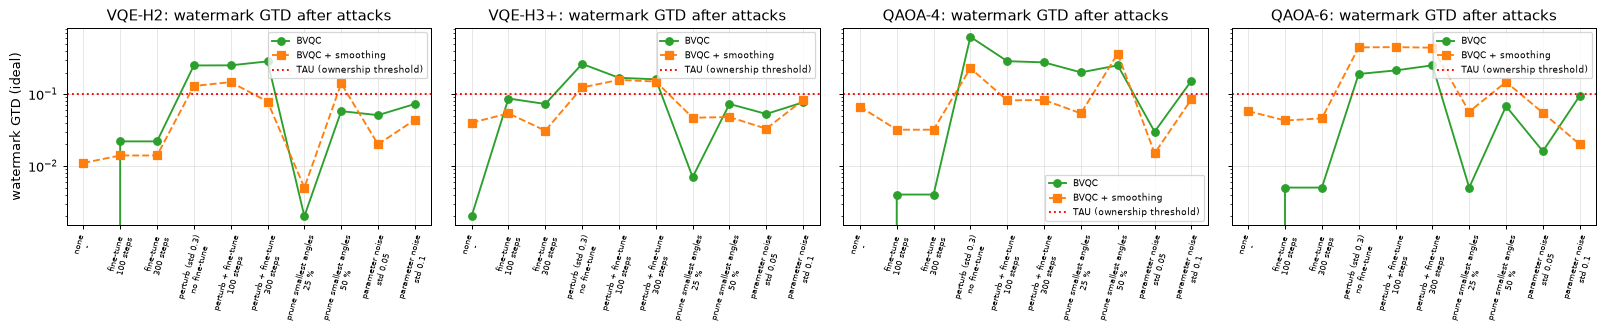

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, name in zip(axes, BENCHMARKS):
    df = ATKDF[ATKDF.benchmark == name].reset_index(drop=True); lab = [f"{a}\n{p}" for a, p in zip(df.attack, df.setting)]
    ax.plot(range(len(df)), df.BVQC_wm_GTD, "o-", color="tab:green", label="BVQC"); ax.plot(range(len(df)), df.smooth_wm_GTD, "s--", color="tab:orange", label="BVQC + smoothing")
    ax.axhline(TAU, color="r", ls=":", label="TAU (ownership threshold)"); ax.set_xticks(range(len(df))); ax.set_xticklabels(lab, rotation=75, fontsize=6); ax.set_yscale("log")
    ax.set_title(f"{name}: watermark GTD after attacks"); ax.legend(fontsize=7)
axes[0].set_ylabel("watermark GTD (ideal)"); plt.tight_layout(); plt.show()

## 10. Side by side with the paper

Each row compares one claim of the paper with the number measured here. Paper values for the four implemented benchmarks are recomputed from Table V (VQE-H2, VQE-H3+, QAOA-4, QAOA-6); averages over all seven benchmarks cannot be reproduced here. Rule used for numeric claims: **reproduced** when within a stated tolerance of the paper, **not reached** when worse, **exceeded** when better than the paper; qualitative claims are **reproduced** or **not reproduced** with the criterion stated in the row; **cannot be checked** when a ingredient (real hardware, the MS baseline, the other benchmarks) is missing.

In [26]:
# Paper numbers (Table V, subset of the four implemented benchmarks); the 'Hanoi' entry holds the paper's Cairo values (Hanoi is the stand-in device here)
P5 = {"Kolkata": dict(NW_base=[0.013, 0.013, 0.031, 0.079], BV_base=[0.015, 0.019, 0.033, 0.086], NW_wm=[0.384, 0.324, 0.715, 1.341], BV_wm=[0.002, 0.017, 0.038, 0.038]),
      "Hanoi":   dict(NW_base=[0.032, 0.068, 0.071, 0.096], BV_base=[0.059, 0.084, 0.064, 0.099], NW_wm=[0.299, 0.265, 0.837, 1.425], BV_wm=[0.017, 0.023, 0.093, 0.101])}
pm = {d: {k: float(np.mean(v)) for k, v in x.items()} for d, x in P5.items()}
nm = {d: NOISY[NOISY.device == d][["NW_base", "BVQC_base", "NW_wm", "BVQC_wm"]].mean() for d in DEVICES}

def numeric_verdict(paper, ours, tol, lower_is_better=True):
    if abs(ours - paper) <= tol:
        return "reproduced"
    return ("exceeded" if ours < paper else "not reached") if lower_is_better else ("exceeded" if ours > paper else "not reached")

rows = []
def add(claim, paper, ours, verdict, ref):
    rows.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": verdict, "where": ref})

for d in DEVICES:
    dv = nm[d]["BVQC_base"] - nm[d]["NW_base"]; dp = pm[d]["BV_base"] - pm[d]["NW_base"]
    add(f"[{d}] BVQC keeps the task GTD (BVQC minus NW, mean of 4 benchmarks)", f"{dp:+.3f} (NW {pm[d]['NW_base']:.3f}, BVQC {pm[d]['BV_base']:.3f})",
        f"{dv:+.3f} (NW {nm[d]['NW_base']:.3f}, BVQC {nm[d]['BVQC_base']:.3f})", "reproduced" if abs(dv) <= 0.02 else "not reproduced", "Table V; tolerance 0.02")
for d in DEVICES:
    add(f"[{d}] watermark GTD of BVQC is small", f"{pm[d]['BV_wm']:.3f}", f"{nm[d]['BVQC_wm']:.3f}", numeric_verdict(pm[d]["BV_wm"], nm[d]["BVQC_wm"], 0.02), "Table V; tolerance 0.02")
for d in DEVICES:
    add(f"[{d}] watermark GTD of unwatermarked circuits is large", f"{pm[d]['NW_wm']:.3f}", f"{nm[d]['NW_wm']:.3f}",
        "reproduced" if nm[d]["NW_wm"] >= 0.25 and nm[d]["NW_wm"] >= 5 * nm[d]["BVQC_wm"] else "not reproduced", "Table V; criterion: >= 0.25 and >= 5x the BVQC value (NW value is set by the drawn groups, MIN_SEP)")
dk = nm["Kolkata"]["BVQC_base"] - nm["Kolkata"]["NW_base"]
add("Fig. 7: mean task-GTD change caused by BVQC (Kolkata)", "+4.1e-3 (7 benchmarks)", f"{dk:+.1e} (4 benchmarks)", "reproduced" if abs(dk) <= 0.01 else "not reproduced", "Fig. 7; tolerance 0.01")
add("Task GTD of BVQC circuits, Kolkata / Cairo (paper) vs Kolkata / Hanoi (here), absolute", "0.041 / 0.070 (7 benchmarks)", f"{nm['Kolkata']['BVQC_base']:.3f} / {nm['Hanoi']['BVQC_base']:.3f} (4 benchmarks, simulated devices)",
    "cannot be checked", "simulated noise differs from real devices; Table V subset of the paper: %.3f / %.3f" % (pm["Kolkata"]["BV_base"], pm["Hanoi"]["BV_base"]))

# grouping (Fig. 4, 5, 6)
pos_lt_rand = [R[n]["arms"]["POS"]["base_gtd"].mean() < R[n]["arms"]["random"]["base_gtd"].mean() for n in BENCHMARKS]
pos_lt_neg = [R[n]["arms"]["POS"]["base_gtd"].mean() < R[n]["arms"]["NEG"]["base_gtd"].mean() for n in BENCHMARKS]
add("Grouping lowers the base-task GTD (POS vs no grouping)", "avg 0.016 with grouping; up to 0.5 without (Fig. 4, 6)",
    "POS %.4f vs random %.4f (mean over benchmarks and samples); POS better on %d/4 benchmarks" % (np.mean([R[n]['arms']['POS']['base_gtd'].mean() for n in BENCHMARKS]),
    np.mean([R[n]['arms']['random']['base_gtd'].mean() for n in BENCHMARKS]), sum(pos_lt_rand)), "reproduced" if (sum(pos_lt_rand) >= 3 and np.mean([R[n]['arms']['POS']['base_gtd'].mean() for n in BENCHMARKS]) <= 0.8 * np.mean([R[n]['arms']['random']['base_gtd'].mean() for n in BENCHMARKS])) else "not reproduced", "Fig. 4/6; criterion: POS better on >= 3 of 4 benchmarks AND mean GTD at least 20 % lower (ideal simulation GTD)")
for n_, pv in (("VQE-H2", "-1.127 (POS) vs -1.0729 (NEG)"), ("VQE-H3+", "-0.078 (POS) vs 0.179 (NEG)")):
    pl, nl = R[n_]["arms"]["POS"]["base"].mean(), R[n_]["arms"]["NEG"]["base"].mean()
    add(f"Fig. 5 {n_}: POS groups reach a lower final training loss than NEG groups", pv, f"{pl:.4f} (POS) vs {nl:.4f} (NEG)", "reproduced" if pl < nl - 0.01 else "not reproduced", "Fig. 5; criterion: POS lower by more than 0.01 (absolute losses depend on the Hamiltonian and ansatz)")
add("Fig. 5 QAOA-4 / QAOA-6 (not in the paper): POS vs NEG final loss", "-", ", ".join("%s %.3f vs %.3f" % (n_, R[n_]["arms"]["POS"]["base"].mean(), R[n_]["arms"]["NEG"]["base"].mean()) for n_ in ("QAOA-4", "QAOA-6")), "cannot be checked", "extension")

# re-compilation (Table III, Fig. 8)
st = pd.DataFrame(STRUCT)
add("Watermark survives re-compilation (value unchanged)", "watermark GTD / task GTD unchanged: 0.263 -> 0.263 (Table III)", "max change of the noise-free watermark value over 7 re-compilations: %.1e" % max(v[1] for v in maxdiff.values()),
    "reproduced" if max(v[1] for v in maxdiff.values()) < 1e-6 else "not reproduced", "Table III, Fig. 8 (BVQC side only)")
add("Circuit structure unchanged by re-compilation (BVQC)", "depth 64, 85 one-qubit, 34 CNOT, mapping unchanged", "unchanged for %d of %d benchmarks (seed 0 vs 7, level 3)" % (st[st.circuit == "BVQC"].same.sum(), len(BENCHMARKS)),
    "reproduced" if st[st.circuit == "BVQC"].same.all() else "not reproduced", "Table III (our compiler / device differ; the unwatermarked NW circuit is unchanged on %d of %d benchmarks, so the changes come from the transpiler seed, not from the watermark; mean |change of noisy task GTD| = %.3f)" % (st[st.circuit == "NW"].same.sum(), len(BENCHMARKS), st[st.circuit == "BVQC"].dgtd.mean()))
add("PPA changes reduced by 9.89e-3 vs the multi-stage watermark MS [12]", "9.89e-3 (Fig. 8)", "MS is not public", "cannot be checked", "Fig. 8")
add("Task GTD reduced by 0.089 vs MS (0.066 Kolkata, 0.112 Cairo)", "0.089 (Fig. 9)", "MS is not public", "cannot be checked", "Fig. 9")
add("Averages over 7 benchmarks incl. VQD-H2, VQD-H3+, GEO-M", "Fig. 7-9", "not implemented (9 / 13 qubit VQD, GEO-M data)", "cannot be checked", "Table IV")

# attacks (Sec. IV-E)
pf = ATKDF[(ATKDF.attack == "perturb + fine-tune") & (ATKDF.setting == f"{ATTACK_STEPS[-1]} steps")]
add("Fine-tuning can remove a backdoor watermark", "stated, no numbers", "perturb + %d fine-tune steps: BVQC watermark GTD %.3f (verified: %s); plain fine-tune of the converged circuit: %.3f" % (
    ATTACK_STEPS[-1], pf.BVQC_wm_GTD.mean(), ", ".join(pf.BVQC_verified), ATKDF[(ATKDF.attack == 'fine-tune')].BVQC_wm_GTD.mean()),
    "reproduced" if pf.BVQC_wm_GTD.mean() > TAU else "not reproduced", "Sec. IV-E; criterion: mean watermark GTD above TAU")
add("Parameter smoothing keeps the watermark after fine-tuning", "stated, no numbers", "perturb + fine-tune: plain %.3f vs smoothed %.3f (verified smooth: %s)" % (pf.BVQC_wm_GTD.mean(), pf.smooth_wm_GTD.mean(), ", ".join(pf.smooth_verified)),
    "reproduced" if pf.smooth_wm_GTD.mean() <= 0.75 * pf.BVQC_wm_GTD.mean() else "not reproduced", "Sec. IV-E; criterion: smoothed watermark GTD at least 25 % lower than plain")
COMP = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 220, "display.width", 250)
display(COMP)
print(COMP.verdict.value_counts().to_dict())

,claim,paper,this notebook,verdict,where
0,"[Kolkata] BVQC keeps the task GTD (BVQC minus NW, mean of 4 benchmarks)","+0.004 (NW 0.034, BVQC 0.038)","-0.001 (NW 0.087, BVQC 0.086)",reproduced,Table V; tolerance 0.02
1,"[Hanoi] BVQC keeps the task GTD (BVQC minus NW, mean of 4 benchmarks)","+0.010 (NW 0.067, BVQC 0.077)","-0.003 (NW 0.052, BVQC 0.049)",reproduced,Table V; tolerance 0.02
2,[Kolkata] watermark GTD of BVQC is small,0.024,0.028,reproduced,Table V; tolerance 0.02
3,[Hanoi] watermark GTD of BVQC is small,0.059,0.013,exceeded,Table V; tolerance 0.02
4,[Kolkata] watermark GTD of unwatermarked circuits is large,0.691,0.512,reproduced,"Table V; criterion: >= 0.25 and >= 5x the BVQC value (NW value is set by the drawn groups, MIN_SEP)"
5,[Hanoi] watermark GTD of unwatermarked circuits is large,0.707,0.511,reproduced,"Table V; criterion: >= 0.25 and >= 5x the BVQC value (NW value is set by the drawn groups, MIN_SEP)"
6,Fig. 7: mean task-GTD change caused by BVQC (Kolkata),+4.1e-3 (7 benchmarks),-1.5e-03 (4 benchmarks),reproduced,Fig. 7; tolerance 0.01
7,"Task GTD of BVQC circuits, Kolkata / Cairo (paper) vs Kolkata / Hanoi (here), absolute",0.041 / 0.070 (7 benchmarks),"0.086 / 0.049 (4 benchmarks, simulated devices)",cannot be checked,simulated noise differs from real devices; Table V subset of the paper: 0.038 / 0.077
8,Grouping lowers the base-task GTD (POS vs no grouping),"avg 0.016 with grouping; up to 0.5 without (Fig. 4, 6)",POS 0.0040 vs random 0.0041 (mean over benchmarks and samples); POS better on 3/4 benchmarks,not reproduced,Fig. 4/6; criterion: POS better on >= 3 of 4 benchmarks AND mean GTD at least 20 % lower (ideal simulation GTD)
9,Fig. 5 VQE-H2: POS groups reach a lower final training loss than NEG groups,-1.127 (POS) vs -1.0729 (NEG),-1.1331 (POS) vs -1.1326 (NEG),not reproduced,Fig. 5; criterion: POS lower by more than 0.01 (absolute losses depend on the Hamiltonian and ansatz)


{'reproduced': 8, 'cannot be checked': 5, 'not reproduced': 5, 'exceeded': 1}


In [27]:
print("Total run time of the notebook: %.1f min (FAST_MODE=%s)" % ((time.time() - T_START) / 60, FAST_MODE))
print("Extension results: true-positive / false-positive rates of the ownership test (TAU=%.2f)" % TAU)
display(pd.DataFrame(VER).T.round(3))

Total run time of the notebook: 35.8 min (FAST_MODE=False)
Extension results: true-positive / false-positive rates of the ownership test (TAU=0.10)


,tpr,fpr_nw,fpr_random,wrong
VQE-H2,1.0,0.162,0.231,0.171
VQE-H3+,1.0,0.338,0.435,0.338
QAOA-4,1.0,0.015,0.008,0.014
QAOA-6,1.0,0.003,0.007,0.024


## Reading the paper critically

* **Simulated devices, not hardware.** The paper's strongest evidence (Table V, Fig. 7-9) comes from real IBM machines with ZNE. Here the noise is gate noise from stored calibration data, evaluated exactly, without shot noise and without readout errors. GTD values are therefore not comparable in absolute terms; the *relations* (BVQC about equal to NW on the task, far below NW on the watermark) are what this notebook can test.
* **What the watermark really is.** Because the VQC is trained on two inputs jointly, the watermark is an extra value of the trained function, not extra gates. That is why re-compilation cannot remove it. The same property means that anything that changes the trained angles (fine-tuning with perturbation, pruning, noise) can erase it; the paper only discusses this in half a page without numbers (section 9 of this notebook measures it).
* **Verification threshold and unambiguity.** The paper never states how close a measured loss has to be to `L_pre` to accept ownership, nor how it handles device noise (watermark GTD on hardware was 0.002 to 0.1). The threshold `TAU` and the false-positive rates in section 8 are our additions; with a small `L_pre` range, an innocent circuit could accidentally match.
* **Overparameterisation helps the owner.** The ansatz is much more expressive than needed for a 4-qubit ground state, which is what leaves room for a second task. Small, tight circuits would show the conflict between the two tasks (the reason for the grouping algorithm) much more strongly.
* **The grouping algorithm is under-specified.** Algorithm 1 accepts a group when the score is *negative*, the text and Fig. 5 call *positive* scores good, Eq. (3) can blow up when the base loss is already close to its optimum (division by a tiny number), and the optimiser used in the scoring steps and the number of steps are not given. We follow the text and rank candidates.
* **The conflict that motivates grouping is weak here.** With an over-parameterised ansatz and 300 Adam steps, the watermarked circuits reach the same base loss as the non-watermarked ones whatever group is drawn (section 5), so POS / NEG / random groups are indistinguishable on the task loss, unlike Fig. 4 and Table III of the paper where an ungrouped watermark costs a GTD of 0.26 to 0.5. Also, when the score of Eq. (3) is evaluated at an already converged circuit the denominator is tiny and the scores explode (up to -1e8), so the ranking is dominated by noise; the paper does not say where the scoring starts.
* **Hyper-parameters.** With the stated learning rate 5e-3 and 300 epochs our VQE circuits do not converge (section 4), so either the authors' initialisation/ansatz differs or TorchQuantum's parameterisation does.
* **The comparison with the multi-stage watermark MS [12] cannot be reproduced** because the implementation and its constraints are not public; the headline numbers (PPA 9.89e-3, GTD 0.089) rest on it.
* **Black-box claim.** Ownership proof requires the owner to reveal `(rho_pre, M_pre, L_pre)` to the verifier; after one verification the group is burnt, so a vendor needs a pool of groups (the paper's 50 groups are exactly such a pool, but this is not discussed).

## Exercises

1. Set `ALPHA = 1`, `BETA = 10` and `BETA = 0.1`. How do the watermark success rate and the base GTD change? Which setting would you use for a production circuit?
2. Replace the random `M_pre` by a single Pauli word and by 10 Pauli words. Does the grouping score still separate POS from NEG candidates?
3. Increase the attacker's noise in "perturb + fine-tune" from 0.3 to 1.0 and plot the watermark GTD against the noise. At which level does plain BVQC lose the watermark and at which level does the smoothed variant?
4. Compute the Probabilistic Proof of Authorship of Eq. (6) for a watermark built from `C` independent constraints (for example `C` different `(rho_pre, M_pre, L_pre)` groups embedded in the same circuit) with `p` taken from the false-positive rate of section 8. How many groups does a PPA below 1e-6 need?
5. Add a VQD benchmark (excited state of H2 with a swap-test overlap term, 9 qubits) to the simulator. Is the watermark as easy to embed as for VQE?